# Actividad práctico-experimental en el entorno académico

## Normalización y estandarización de datos médicos con CRISP-DM

![Logo del ITQ](img/ITQlogo.png)

| Campo | Información |
|---|---|
| **Cargo** | Docente Especialista |
| **Nombre del docente** | Ing. Elvis Pachacama Cabezas |
| **Asignatura** | Fundamentos de Machine Learning |
| **Carrera** | Inteligencia Artificial |
| **Estudiante** | Edgar Enrique Crespo Ch. |
| **Fecha** | 20-11-2026 |
| **Link de repositorio** | https://github.com/EdgarCrespo73/Fundamentos_de_machine_learning_ITQ/blob/main/Programa3EjercicioCompleto_explicado.ipynb
**Fuente de los datos:** Clore, J., Cios, K., DeShazo, J., y Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J


## Objetivos

Aplicar las fases de comprensión del negocio y comprensión de los datos de CRISP-DM, y desarrollar la preparación de datos hasta la normalización Min-Max y la estandarización Z-score, mediante el análisis reproducible de más de 100 000 registros de hospitalizaciones de pacientes con diabetes en Python.

**Alcance metodológico:** fases 1 y 2 de CRISP-DM completas; fase 3 hasta selección, limpieza y escalamiento. No se entrena ni evalúa ningún modelo.

---
# Paso 1. Descarga y registro de la fuente

Fuente oficial y diccionario de variables: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

**Celda 1 – Instalación del paquete de descarga**


In [1]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


### Explicación línea por línea: Celda de instalación

- `%pip install -q ucimlrepo`: `%pip` es un comando  de Jupyter que ejecuta `pip` dentro del entorno del kernel actual (así el paquete queda disponible en este cuaderno). `install` instala el paquete; `-q` (quiet) reduce los mensajes de salida; `ucimlrepo` es la librería oficial para descargar conjuntos de datos del repositorio UCI Machine Learning.

**Celda 2 – Descarga y copia local** (se mantiene `df` como copia original sin modificar).

In [2]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=296)
df = dataset.data.original.copy()

print("Filas y columnas:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100.000 registros."

display(df.head())
display(dataset.variables)

df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)

Filas y columnas: (101766, 50)


C:\Users\Usuario\anaconda3\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


### Explicación línea por línea: Descarga y copia local

- `from ucimlrepo import fetch_ucirepo`: importa solo la función `fetch_ucirepo`, que descarga un dataset del repositorio UCI a partir de su número de identificación.
- `dataset = fetch_ucirepo(id=296)`: descarga el conjunto *Diabetes 130-US hospitals* (id 296). Devuelve un objeto que contiene los datos (`data`), los metadatos (`metadata`) y la descripción de variables (`variables`).
- `df = dataset.data.original.copy()`: toma la tabla completa original (características + objetivo en un solo DataFrame) y crea una copia independiente con `.copy()`, de modo que los cambios futuros no alteren el objeto descargado.
- `print("Filas y columnas:", df.shape)`: imprime una tupla `(n_filas, n_columnas)`; `shape` es el atributo que da las dimensiones del DataFrame.
- `assert len(df) > 100_000, "..."`: *aserción*: comprueba que el número de filas (`len(df)`) supere 100 000 (el guion bajo en `100_000` es solo un separador visual). Si es falso, el programa se detiene y muestra el mensaje indicado.
- `display(df.head())`: muestra en formato de tabla las primeras 5 filas (`head()`); `display` es la función de Jupyter para mostrar objetos con formato enriquecido.
- `display(dataset.variables)`: muestra la tabla de metadatos de cada variable: nombre, rol, tipo, descripción, unidades y si tiene valores faltantes.
- `df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)`: guarda el DataFrame en un archivo CSV como respaldo de la fuente; `index=False` evita escribir el índice como columna extra.

**Registro de la descarga:** fecha dimensiones y versiones de las bibliotecas utilizadas

In [3]:
import sys, platform, datetime
import numpy as np, pandas as pd, matplotlib, seaborn as sns, sklearn
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from importlib.metadata import version 

### Explicación línea por línea: Importaciones y registro de versiones

- `import sys, platform, datetime`: importa tres módulos de la biblioteca estándar: `sys` (información del intérprete), `platform` (datos de la plataforma, p. ej. versión de Python) y `datetime` (fechas y horas).
- `import numpy as np, pandas as pd, matplotlib, seaborn as sns, sklearn`: importa las bibliotecas científicas con alias convencionales: `np` (cálculo numérico), `pd` (tablas de datos), `matplotlib` (gráficos base), `sns` (gráficos estadísticos) y `sklearn` (scikit-learn, aprendizaje automático).
- `import matplotlib.pyplot as plt`: importa la interfaz `pyplot` de matplotlib con el alias `plt`, usada para crear figuras y ejes.
- `from sklearn.preprocessing import MinMaxScaler, StandardScaler`: importa las dos clases de escalamiento: `MinMaxScaler` (normalización a un rango) y `StandardScaler` (estandarización Z-score).
- `from importlib.metadata import version`: importa la función `version`, que devuelve la versión instalada de cualquier paquete a partir de su nombre.

In [4]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

df_original = df.copy()

registro = {
    "Fecha de descarga": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
    "Filas x columnas": f"{df.shape[0]:,} x {df.shape[1]}",
    "Python": platform.python_version(),
    "ucimlrepo": version("ucimlrepo"),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "scikit-learn": sklearn.__version__,
}

pd.Series(registro, name="Valor").to_frame()

,Valor
Fecha de descarga,2026-11-20 17:46
Filas x columnas,"101,766 x 50"
Python,3.14.6
ucimlrepo,0.0.7
pandas,3.1.1
numpy,2.5.3
matplotlib,3.11.0
seaborn,0.13.2
scikit-learn,1.9.1


### Explicación línea por línea: Opciones de visualización y registro de la descarga

- `pd.set_option("display.max_columns", 60)`: configura pandas para mostrar hasta 60 columnas sin abreviarlas con puntos suspensivos.
- `pd.set_option("display.width", 200)`: fija en 200 caracteres el ancho de salida de las tablas antes de saltar de línea.
- `sns.set_theme(style="whitegrid")`: aplica el tema global de seaborn con fondo blanco y cuadrícula (`whitegrid`) a todos los gráficos.
- `df_original = df.copy()`: guarda una copia intacta del dataset descargado; será el punto de partida de la limpieza para no modificar la fuente.
- `registro = { ... }`: crea un *diccionario* (pares clave: valor) con la ficha técnica de la descarga:
- `"Fecha de descarga": datetime.datetime.now().strftime("%Y-%m-%d %H:%M")`: `now()` obtiene la fecha y hora actuales y `strftime` las convierte a texto con el formato año-mes-día hora:minuto.
- `"Filas x columnas": f"{df.shape[0]:,} x {df.shape[1]}"`: *f-string* que inserta el número de filas con separador de miles (`:,`) y el número de columnas.
- `"Python": platform.python_version()`: versión del intérprete de Python en uso.
- `"ucimlrepo": version("ucimlrepo")`: versión instalada del paquete de descarga (se consulta por nombre con `importlib.metadata`).
- `"pandas": pd.__version__ , "numpy": np.__version__ , ...`: cada biblioteca expone su versión en el atributo `__version__`; se registran pandas, numpy, matplotlib, seaborn y scikit-learn para garantizar la reproducibilidad.
- `pd.Series(registro, name="Valor").to_frame()`: convierte el diccionario en una `Series` (columna indexada por las claves) con nombre `Valor` y luego en DataFrame con `to_frame()`. Al ser la última expresión de la celda, Jupyter la muestra automáticamente.


# Paso 2. Fase 1 – Comprensión del negocio

### 2.1 El problema de las readmisiones hospitalarias
Una readmisión ocurre cuando un paciente que fue dado de alta vuelve a ser hospitalizado. En pacientes con diabetes las readmisiones pueden indicar un control inadecuado de la enfermedad, una alta prematura, un seguimiento ambulatorio insuficiente o complicaciones. Son costosas para el sistema de salud y se usan como indicador de calidad de la atención.

**Actores interesados:** pacientes y familias; médicos y personal de enfermería; administradores hospitalarios; aseguradoras y entes reguladores; y los equipos de ciencia de datos que apoyan la toma de decisiones.

**Utilidad de explorar antes de modelar:** permite conocer la calidad de los datos (faltantes, duplicados, inconsistencias), entender las distribuciones y escalas de las variables y decidir con criterio qué limpieza y qué transformación aplicar. Variables con escalas muy distintas (p. ej. 1–14 días frente a 1–132 pruebas de laboratorio) pueden dominar a las demás en métodos basados en distancias o gradientes si no se escalan.

### 2.2 Objetivo, preguntas y criterios de éxito
**Objetivo general:** explorar cómo se distribuyen las características de las hospitalizaciones de pacientes con diabetes y cómo se relacionan *descriptivamente* con la readmisión, dejando las variables cuantitativas listas en dos versiones comparables (normalizada y estandarizada).

**Preguntas de análisis**
1. ¿Cómo se distribuyen las variables cuantitativas de la hospitalización (duración, procedimientos, medicamentos, visitas previas) y qué tan asimétricas son?
2. ¿Cómo se reparte la variable `readmitted` y cómo difieren, de forma descriptiva, las variables cuantitativas entre las categorías `NO`, `<30` y `>30`?
3. ¿Qué calidad tienen los datos (faltantes, duplicados, atípicos) y qué decisiones de limpieza se justifican?

**Criterios verificables de éxito**
- El conjunto de entrada y el de salida conservan más de 100 000 filas, con trazabilidad de cada decisión.
- Las 7 variables cuantitativas no tienen nulos y se exportan con el mismo orden e índice en ambas versiones.
- Tras Min-Max: mínimo = 0 y máximo = 1 (tolerancia numérica). Tras Z-score: media ≈ 0 y desviación (`ddof=0`) ≈ 1.
- Se contrastan manualmente 5 valores con la salida de scikit-learn y coinciden.

### 2.3 Variable de referencia `readmitted`
Según la documentación de UCI: **`NO`** = sin registro de readmisión; **`<30`** = readmitido en menos de 30 días; **`>30`** = readmitido después de 30 días. Es la variable de referencia del análisis y no se escala (es categórica).

### 2.4 Límites y consideraciones éticas
- **Periodo 1999–2008:** las prácticas clínicas, los medicamentos y los registros han cambiado; los resultados no se pueden extrapolar sin cautela a hoy.
- **Población:** solo hospitalizaciones en 130 hospitales de EE. UU. (no representa a otros países ni al nivel ambulatorio).
- **Varias hospitalizaciones por paciente:** una fila es una *hospitalización*, no un paciente; un mismo `patient_nbr` aparece varias veces, por lo que las filas no son estrictamente independientes.
- **Confidencialidad:** los datos están anonimizados. No se intenta reidentificar a ninguna persona; los identificadores se usan solo como referencia de fila.
- El análisis es académico: no emite diagnósticos ni establece relaciones causales.

# Paso 3. Fase 2 – Comprensión de los datos

### 3.1 Dimensiones reales: hospitalizaciones vs. pacientes únicos

In [5]:
     
n_filas, n_cols = df.shape
n_hosp = df["encounter_id"].nunique()
n_pac = df["patient_nbr"].nunique()

print(f"Filas x columnas ........... {n_filas:,} x {n_cols}")
print(f"Hospitalizaciones (encounter_id únicos) ... {n_hosp:,}")
print(f"Pacientes únicos (patient_nbr) ........... {n_pac:,}")
print(f"Pacientes con más de una hospitalización .. {(df.groupby('patient_nbr').size() > 1).sum():,}")
assert n_filas == 101_766, "Se esperaban 101 766 filas"

display(df.groupby("patient_nbr").size().value_counts().sort_index().head(8)
        .rename("pacientes").rename_axis("hospitalizaciones por paciente").to_frame())

Filas x columnas ........... 101,766 x 50
Hospitalizaciones (encounter_id únicos) ... 101,766
Pacientes únicos (patient_nbr) ........... 71,518
Pacientes con más de una hospitalización .. 16,773


,pacientes
hospitalizaciones por paciente,
1,54745
2,10434
3,3328
4,1421
5,717
6,346
7,207
8,111


### Explicación línea por línea: Dimensiones reales: hospitalizaciones vs. pacientes

- `n_filas, n_cols = df.shape`: *desempaquetado de tupla*: asigna el número de filas a `n_filas` y el de columnas a `n_cols`.
- `n_hosp = df["encounter_id"].nunique()`: `nunique()` cuenta valores distintos; como `encounter_id` identifica cada hospitalización, da el total de hospitalizaciones únicas.
- `n_pac = df["patient_nbr"].nunique()`: cuenta los pacientes distintos (`patient_nbr` identifica al paciente).
- `print(f"Filas x columnas ... {n_filas:,} x {n_cols}")`: imprime las dimensiones con formato de miles.
- `print(f"Hospitalizaciones (encounter_id únicos) ... {n_hosp:,}")`: imprime el total de hospitalizaciones únicas.
- `print(f"Pacientes únicos (patient_nbr) ... {n_pac:,}")`: imprime el total de pacientes únicos.
- `(df.groupby('patient_nbr').size() > 1).sum()`: `groupby` agrupa las filas por paciente; `size()` cuenta las filas de cada grupo; `> 1` genera valores booleanos (True si el paciente tiene más de una hospitalización); `sum()` suma los True, es decir, cuenta esos pacientes.
- `assert n_filas == 101_766, "..."`: verifica que el dataset tenga exactamente 101 766 filas, el valor documentado en la fuente.
- `df.groupby("patient_nbr").size().value_counts().sort_index().head(8)`: cadena de métodos: cuenta filas por paciente → `value_counts()` cuenta cuántos pacientes tienen 1, 2, 3… hospitalizaciones → `sort_index()` ordena por ese número → `head(8)` conserva los 8 primeros.
- `.rename("pacientes").rename_axis("hospitalizaciones por paciente").to_frame()`: `rename` nombra la columna de valores, `rename_axis` nombra el índice y `to_frame()` convierte la Series en tabla; `display(...)` la muestra.

**Interpretación.** Se cargaron las 101 766 hospitalizaciones esperadas, correspondientes a 71 518 pacientes únicos. Es decir, hay 30 000 filas "extra" porque muchos pacientes fueron hospitalizados más de una vez (16 773 pacientes aparecen en 2 o más filas). Por eso hay que distinguir *hospitalizaciones* de *pacientes*: contar filas no es contar personas.

### 3.2 Diccionario de variables (todas las columnas)
Se combina lo observado en los datos (tipo `pandas`, nº de valores distintos, ejemplos) con el significado de la documentación UCI y una **clasificación conceptual** propia. Recordatorio: *un número almacenado no implica una variable cuantitativa*.

In [6]:
var = dataset.variables.set_index("name")

# Clasificación conceptual y rol analítico (criterio propio, a partir de la documentación)
cuantitativas = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                 "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
identificadores = ["encounter_id", "patient_nbr"]
cat_codificadas = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
ordinales = ["age"]
medicamentos = ["metformin","repaglinide","nateglinide","chlorpropamide","glimepiride","acetohexamide",
                "glipizide","glyburide","tolbutamide","pioglitazone","rosiglitazone","acarbose","miglitol",
                "troglitazone","tolazamide","examide","citoglipton","insulin","glyburide-metformin",
                "glipizide-metformin","glimepiride-pioglitazone","metformin-rosiglitazone","metformin-pioglitazone"]

def tipo_conceptual(c):
    if c in identificadores: return "Identificador"
    if c in cuantitativas: return "Cuantitativa discreta (conteo)"
    if c in cat_codificadas: return "Categórica nominal (código numérico)"
    if c in ordinales: return "Categórica ordinal (intervalos)"
    if c == "readmitted": return "Categórica ordinal (objetivo)"
    if c in medicamentos: return "Categórica ordinal (estado de dosis)"
    if c in ("diag_1","diag_2","diag_3"): return "Categórica nominal (código ICD-9)"
    if c == "weight": return "Cuantitativa en intervalos (categórica)"
    return "Categórica nominal"
def rol(c):
    if c in identificadores: return "Referencia de fila (no escalar)"
    if c == "readmitted": return "Variable de referencia / objetivo (no escalar)"
    if c in ["time_in_hospital","num_lab_procedures","num_procedures","num_medications",
             "number_outpatient","number_emergency","number_inpatient"]: return "Variable a escalar (Pasos 6-7)"
    if c == "number_diagnoses": return "Cuantitativa complementaria (no escalada)"
    return "Descriptiva / categórica (no escalar)"

def unidades(c):
    u = {"time_in_hospital":"días","num_lab_procedures":"nº de pruebas","num_procedures":"nº de procedimientos",
         "num_medications":"nº de fármacos distintos","number_outpatient":"nº de visitas (año previo)",
         "number_emergency":"nº de visitas (año previo)","number_inpatient":"nº de ingresos (año previo)",
         "number_diagnoses":"nº de diagnósticos","weight":"libras, en intervalos","age":"intervalos de 10 años"}
    if c in u: return u[c]
    if c in identificadores: return "código único"
    s = df[c]
    if s.nunique(dropna=True) <= 6:
        return "categorías: " + ", ".join(map(str, s.dropna().unique()[:6]))
    return f"{s.nunique(dropna=True)} categorías/códigos"

dic = pd.DataFrame({
    "tipo_observado": df.dtypes.astype(str),
    "n_distintos": df.nunique(dropna=True),
    "significado": [str(var.loc[c, "description"]).split(". ")[0][:110] if c in var.index else "" for c in df.columns],
    "tipo_conceptual": [tipo_conceptual(c) for c in df.columns],
    "unidades_o_categorias": [unidades(c) for c in df.columns],
    "rol_analitico": [rol(c) for c in df.columns],
})
dic.index.name = "variable"
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 70):
    display(dic)

    

,tipo_observado,n_distintos,significado,tipo_conceptual,unidades_o_categorias,rol_analitico
variable,,,,,,
encounter_id,int64,101766,Unique identifier of an encounter,Identificador,código único,Referencia de fila (no escalar)
patient_nbr,int64,71518,Unique identifier of a patient,Identificador,código único,Referencia de fila (no escalar)
race,str,5,"Values: Caucasian, Asian, African American, Hispanic, and other",Categórica nominal,"categorías: Caucasian, AfricanAmerican, Other, Asian, Hispanic",Descriptiva / categórica (no escalar)
gender,str,3,"Values: male, female, and unknown/invalid",Categórica nominal,"categorías: Female, Male, Unknown/Invalid",Descriptiva / categórica (no escalar)
age,str,10,"Grouped in 10-year intervals: [0, 10), [10, 20),..., [90, 100)",Categórica ordinal (intervalos),intervalos de 10 años,Descriptiva / categórica (no escalar)
weight,str,9,Weight in pounds.,Cuantitativa en intervalos (categórica),"libras, en intervalos",Descriptiva / categórica (no escalar)
admission_type_id,int64,8,"Integer identifier corresponding to 9 distinct values, for example...",Categórica nominal (código numérico),8 categorías/códigos,Descriptiva / categórica (no escalar)
discharge_disposition_id,int64,26,"Integer identifier corresponding to 29 distinct values, for exampl...",Categórica nominal (código numérico),26 categorías/códigos,Descriptiva / categórica (no escalar)
admission_source_id,int64,17,"Integer identifier corresponding to 21 distinct values, for exampl...",Categórica nominal (código numérico),17 categorías/códigos,Descriptiva / categórica (no escalar)


### Explicación línea por línea: Diccionario de variables (clasificación conceptual)


**Preparación de metadatos y listas de clasificación**

- `var = dataset.variables.set_index("name")`: toma la tabla de metadatos y usa la columna `name` como índice, para consultar cada variable por su nombre con `.loc`.
- `cuantitativas = [...]`: lista de las 8 columnas que son conteos o duraciones (variables cuantitativas discretas).
- `identificadores = [...]`: lista con `encounter_id` y `patient_nbr`: códigos de referencia, no magnitudes.
- `cat_codificadas = [...]`: lista de columnas que son categorías almacenadas como número (tipo de admisión, destino al alta, origen de admisión); sus números no tienen sentido aritmético.
- `ordinales = ["age"]`: `age` está en intervalos de 10 años con orden natural (categórica ordinal).
- `medicamentos = [...]`: lista de las 23 columnas de medicamentos, cuyo valor indica el estado de la dosis (No, Steady, Up, Down).

**Función tipo_conceptual(c)**

- `def tipo_conceptual(c):`: define una función que recibe el nombre de una columna `c` y devuelve su tipo conceptual.
- `if c in identificadores: return "Identificador"`: `in` comprueba pertenencia a una lista; `return` devuelve el resultado y termina la función. Las líneas `if` siguientes aplican la misma lógica a cada grupo (cuantitativa discreta, categórica nominal codificada, ordinal, objetivo `readmitted`, medicamento, diagnósticos ICD-9 y `weight`).
- `if c in ("diag_1","diag_2","diag_3")`: los tres diagnósticos usan códigos ICD-9 (Clasificación Internacional de Enfermedades, 9.ª revisión), por eso son categóricos nominales.
- `return "Categórica nominal"`: valor por defecto: si ninguna condición anterior se cumple, la columna se considera categórica nominal.

**Función rol(c)**

- `def rol(c):`: define el papel de la columna dentro del análisis.
- `if c in identificadores: return "Referencia de fila (no escalar)"`: los identificadores sirven solo para referenciar filas y no se escalan.
- `if c == "readmitted": ...`: `readmitted` es la variable objetivo; tampoco se escala.
- `if c in ["time_in_hospital", ...]: return "Variable a escalar (Pasos 6-7)"`: las siete variables cuantitativas elegidas serán normalizadas y estandarizadas.
- `if c == "number_diagnoses": ...`: cuantitativa complementaria que no se escala en la práctica.
- `return "Descriptiva / categórica (no escalar)"`: rol por defecto del resto de columnas.

**Función unidades(c)**

- `def unidades(c):`: devuelve las unidades o categorías de la columna.
- `u = {"time_in_hospital":"días", ...}`: diccionario que asocia cada variable cuantitativa (más `weight` y `age`) con su unidad de medida.
- `if c in u: return u[c]`: si la variable está en el diccionario, devuelve su unidad buscando por clave.
- `if c in identificadores: return "código único"`: los identificadores no tienen unidades.
- `s = df[c]`: extrae la columna como Series para analizarla.
- `if s.nunique(dropna=True) <= 6:`: si la columna tiene 6 o menos valores distintos (ignorando nulos con `dropna=True`), se listan sus categorías.
- `return "categorías: " + ", ".join(map(str, s.dropna().unique()[:6]))`: `dropna()` quita nulos, `unique()` obtiene valores distintos, `[:6]` toma los 6 primeros, `map(str, ...)` los convierte a texto y `", ".join(...)` los une separados por comas.
- `return f"{s.nunique(dropna=True)} categorías/códigos"`: si hay más de 6 valores distintos solo se informa cuántos son.

**Construcción de la tabla `dic`**

- `dic = pd.DataFrame({ ... })`: crea un DataFrame a partir de un diccionario donde cada clave será una columna:
- `"tipo_observado": df.dtypes.astype(str)`: tipo de dato que pandas detectó (`int64`, `object`…) convertido a texto.
- `"n_distintos": df.nunique(dropna=True)`: número de valores distintos por columna.
- `"significado": [str(var.loc[c, "description"]).split(". ")[0][:110] if c in var.index else "" for c in df.columns]`: *list comprehension*: para cada columna toma su descripción oficial, la convierte en texto, la parte por ". " (`split`), se queda con la primera frase (`[0]`) y la recorta a 110 caracteres (`[:110]`); si la columna no está en los metadatos deja una cadena vacía.
- `"tipo_conceptual": [tipo_conceptual(c) for c in df.columns]`: aplica la función a cada columna.
- `"unidades_o_categorias": [unidades(c) for c in df.columns]`: aplica la función de unidades a cada columna.
- `"rol_analitico": [rol(c) for c in df.columns]`: aplica la función de rol a cada columna.
- `dic.index.name = "variable"`: pone nombre al índice de la tabla.
- `with pd.option_context("display.max_rows", 100, "display.max_colwidth", 70):`: bloque `with` que cambia temporalmente las opciones de pandas (hasta 100 filas y 70 caracteres por celda) y las restaura al salir.
- `display(dic)`: muestra el diccionario de variables dentro del bloque con las opciones temporales.

**Interpretación.**
- Hay 13 columnas almacenadas como enteros, pero no todas son cuantitativas: `encounter_id` y `patient_nbr` son identificadores, y `admission_type_id`, `discharge_disposition_id` y `admission_source_id` son códigos de categorías(restar o promediar el "código 7" y el "código 1" no tiene sentido).
- `age` y `weight` vienen en intervalos (p. ej. `[70-80)`), por lo que no son edad/peso continuos.
- Las 23 columnas de medicamentos son estados (`No`, `Steady`, `Up`, `Down`); `examide` y `citoglipton` tienen un único valor (constantes) y no aportan información.
- Solo los conteos de hospitalización (días, procedimientos, medicamentos, visitas previas) son genuinamente cuantitativos; esas siete variables serán las escaladas.


### 3.3 Datos faltantes por columna (nulos y marcadores `?`)

In [24]:
# 1) Nulos reales de pandas  2) marcadores "?" (en esta versión ya vienen convertidos a NaN)
nulos = df.isna().sum()
signo = (df.astype(str) == "?").sum()
faltantes = pd.DataFrame({"nulos": nulos, "marcador_?": signo})
faltantes["total_faltante"] = faltantes["nulos"] + faltantes["marcador_?"]
faltantes["porcentaje"] = (faltantes["total_faltante"] / len(df) * 100).round(2)
faltantes = faltantes[faltantes["total_faltante"] > 0].sort_values("porcentaje", ascending=False)
display(faltantes)
print("Columnas con faltantes:", len(faltantes), "de", df.shape[1])

,nulos,marcador_?,total_faltante,porcentaje
weight,98569,0,98569,96.86
max_glu_serum,96420,0,96420,94.75
A1Cresult,84748,0,84748,83.28
medical_specialty,49949,0,49949,49.08
payer_code,40256,0,40256,39.56
race,2273,0,2273,2.23
diag_3,1423,0,1423,1.40
diag_2,358,0,358,0.35
diag_1,21,0,21,0.02


Columnas con faltantes: 9 de 50


### Explicación línea por línea: Datos faltantes por columna

- `nulos = df.isna().sum()`: `isna()` devuelve una tabla de True/False donde hay valores nulos (NaN); `sum()` suma los True por columna.
- `signo = (df.astype(str) == "?").sum()`: convierte todo a texto, compara con el marcador "?" (que algunos datasets usan para indicar faltante) y cuenta coincidencias por columna.
- `faltantes = pd.DataFrame({"nulos": nulos, "marcador_?": signo})`: junta ambos conteos en una tabla de dos columnas.
- `faltantes["total_faltante"] = faltantes["nulos"] + faltantes["marcador_?"]`: crea la columna con el total de faltantes sumando ambos tipos.
- `faltantes["porcentaje"] = (faltantes["total_faltante"] / len(df) * 100).round(2)`: calcula el porcentaje de faltantes respecto al total de filas y redondea a 2 decimales.
- `faltantes = faltantes[faltantes["total_faltante"] > 0].sort_values("porcentaje", ascending=False)`: *filtrado booleano*: conserva solo columnas con algún faltante y las ordena de mayor a menor porcentaje.
- `display(faltantes)`: muestra la tabla.
- `print("Columnas con faltantes:", len(faltantes), "de", df.shape[1])`: imprime cuántas columnas tienen faltantes sobre el total de columnas.

**Interpretación y tratamiento de categorías `None`.**
- `weight` (96.9 %), `max_glu_serum` (94.7 %), `A1Cresult` (83.3 %), `medical_specialty` (49.1 %) y `payer_code` (39.6 %) concentran los faltantes. `race`, `diag_1/2/3` tienen porcentajes bajos (≤ 2.3 %).
- **Ojo con `None`:** según la documentación, en `max_glu_serum` y `A1Cresult` el valor `None` significa **"prueba no realizada"**, que es información clínica válida y *no* un dato perdido. El lector de la API los muestra como `NaN`, así que ese porcentaje alto es en realidad "no medido". No se imputan ni se eliminan; si se usaran, se codificarían como una categoría propia ("no medido").
- `weight` sí es un faltante real (casi todo vacío): sería la primera candidata a descartarse en un análisis posterior.
- Ninguna de las siete variables cuantitativas elegidas tiene faltantes (se verifica en el Paso 

### 3.4 Duplicados (filas e identificadores)

In [25]:
print("Filas completamente duplicadas ............:", df.duplicated().sum())
print("encounter_id duplicados ....................:", df["encounter_id"].duplicated().sum())
print("Filas con patient_nbr repetido (hospitalizaciones de un mismo paciente):",
      df["patient_nbr"].duplicated(keep=False).sum())

# Ejemplo: un paciente con varias hospitalizaciones válidas (distinto encounter_id y valores distintos)
pac = df["patient_nbr"].value_counts().index[0]
display(df[df["patient_nbr"] == pac][["encounter_id","patient_nbr","time_in_hospital","num_medications","number_inpatient","readmitted"]].head(8))

Filas completamente duplicadas ............: 0
encounter_id duplicados ....................: 0
Filas con patient_nbr repetido (hospitalizaciones de un mismo paciente): 47021


,encounter_id,patient_nbr,time_in_hospital,num_medications,number_inpatient,readmitted
38307,119039172,88785891,1,10,0,>30
40252,125094312,88785891,1,10,2,<30
40661,126171582,88785891,5,15,3,>30
44515,137245596,88785891,2,8,5,<30
45147,139425576,88785891,2,4,6,<30
45986,141994242,88785891,4,14,7,<30
50167,150986298,88785891,1,9,9,<30
50393,151413846,88785891,4,19,9,<30


### Explicación línea por línea: Duplicados

- `print("Filas completamente duplicadas ...:", df.duplicated().sum())`: `duplicated()` marca con True las filas idénticas a una anterior; `sum()` las cuenta.
- `df["encounter_id"].duplicated().sum()`: cuenta identificadores de hospitalización repetidos (debería ser 0 porque son únicos).
- `df["patient_nbr"].duplicated(keep=False).sum()`: `keep=False` marca *todas* las apariciones de un paciente repetido (no solo las posteriores), contando así todas las filas que pertenecen a pacientes con varias hospitalizaciones.
- `pac = df["patient_nbr"].value_counts().index[0]`: `value_counts()` ordena los pacientes por número de filas; `.index[0]` toma el primero, es decir, el paciente con más hospitalizaciones.
- `display(df[df["patient_nbr"] == pac][[...]].head(8))`: filtra las filas de ese paciente, selecciona solo 6 columnas (doble corchete = lista de columnas) y muestra las 8 primeras, para ejemplificar que son hospitalizaciones distintas y válidas.

**Interpretación.** No hay filas duplicadas ni `encounter_id` repetidos, por lo que no se elimina nada. La repetición de `patient_nbr` es esperable: cada fila es una hospitalización distinta (con su propio `encounter_id` y valores distintos), así que son registros válidos y eliminarlos sería perder información. Sí es una limitación a tener presente: las filas de un mismo paciente no son independiente

### 3.5 Estadística descriptiva de las variables cuantitativas y frecuencias de readmitted

In [26]:
VARS = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
        "number_outpatient", "number_emergency", "number_inpatient"]

desc = df[VARS].agg(["min", "max", "mean", "median", "std"]).T
desc[["Q1", "Q3"]] = df[VARS].quantile([0.25, 0.75]).T.values
desc["asimetría"] = df[VARS].skew()
display(desc.round(3))

freq = df["readmitted"].value_counts()
frecs = pd.DataFrame({"hospitalizaciones": freq, "porcentaje": (freq / len(df) * 100).round(2)})
display(frecs)

,min,max,mean,median,std,Q1,Q3,asimetría
time_in_hospital,1.0,14.0,4.396,4.0,2.985,2.0,6.0,1.134
num_lab_procedures,1.0,132.0,43.096,44.0,19.674,31.0,57.0,-0.237
num_procedures,0.0,6.0,1.340,1.0,1.706,0.0,2.0,1.316
num_medications,1.0,81.0,16.022,15.0,8.128,10.0,20.0,1.327
number_outpatient,0.0,42.0,0.369,0.0,1.267,0.0,0.0,8.833
number_emergency,0.0,76.0,0.198,0.0,0.930,0.0,0.0,22.856
number_inpatient,0.0,21.0,0.636,0.0,1.263,0.0,1.0,3.614


,hospitalizaciones,porcentaje
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


### Explicación línea por línea: Estadística descriptiva y frecuencias

- `VARS = [...]`: lista con las 7 variables cuantitativas de trabajo; se reutilizará en todo el cuaderno.
- `desc = df[VARS].agg(["min", "max", "mean", "median", "std"]).T`: `agg` calcula varias funciones de resumen por columna (mínimo, máximo, media, mediana y desviación estándar); `.T` transpone para que cada variable sea una fila.
- `desc[["Q1", "Q3"]] = df[VARS].quantile([0.25, 0.75]).T.values`: `quantile` calcula el percentil 25 y 75 (primer y tercer cuartil); se transpone y se toman los valores (`.values`) para asignarlos como dos columnas nuevas.
- `desc["asimetría"] = df[VARS].skew()`: `skew()` calcula el coeficiente de asimetría (positivo = cola larga a la derecha).
- `display(desc.round(3))`: muestra la tabla con 3 decimales.
- `freq = df["readmitted"].value_counts()`: cuenta cuántas hospitalizaciones hay en cada categoría de readmisión (NO, >30, <30).
- `frecs = pd.DataFrame({"hospitalizaciones": freq, "porcentaje": (freq / len(df) * 100).round(2)})`: arma una tabla con la frecuencia absoluta y la relativa en porcentaje.
- `display(frecs)`: muestra la tabla de frecuencias.

**Interpretación.**
- `time_in_hospital`: de 1 a 14 días, media ≈ 4.4 y mediana 4; ligera asimetría positiva.
- `num_lab_procedures` es la única casi simétrica (media 43.1, mediana 44) y tiene la **mayor escala** (hasta 132); `num_medications` llega a 81.
- `number_outpatient`, `number_emergency` y `number_inpatient` tienen mediana 0 y colas larguísimas (máximos 42, 76 y 21): son **conteos muy sesgados**, con asimetrías de 8.8, 22.9 y 3.6.
- `readmitted`: ≈ 53.9 % `NO`, 34.9 % `>30` y 11.2 % `<30`. Aproximadamente **46 %** de las hospitalizaciones termina en algún tipo de readmisión; la clase `<30` es la minoritaria (relevante si luego se modelara).

### 3.6 Visualizaciones (histogramas, diagramas de caja y frecuencias de readmitted)

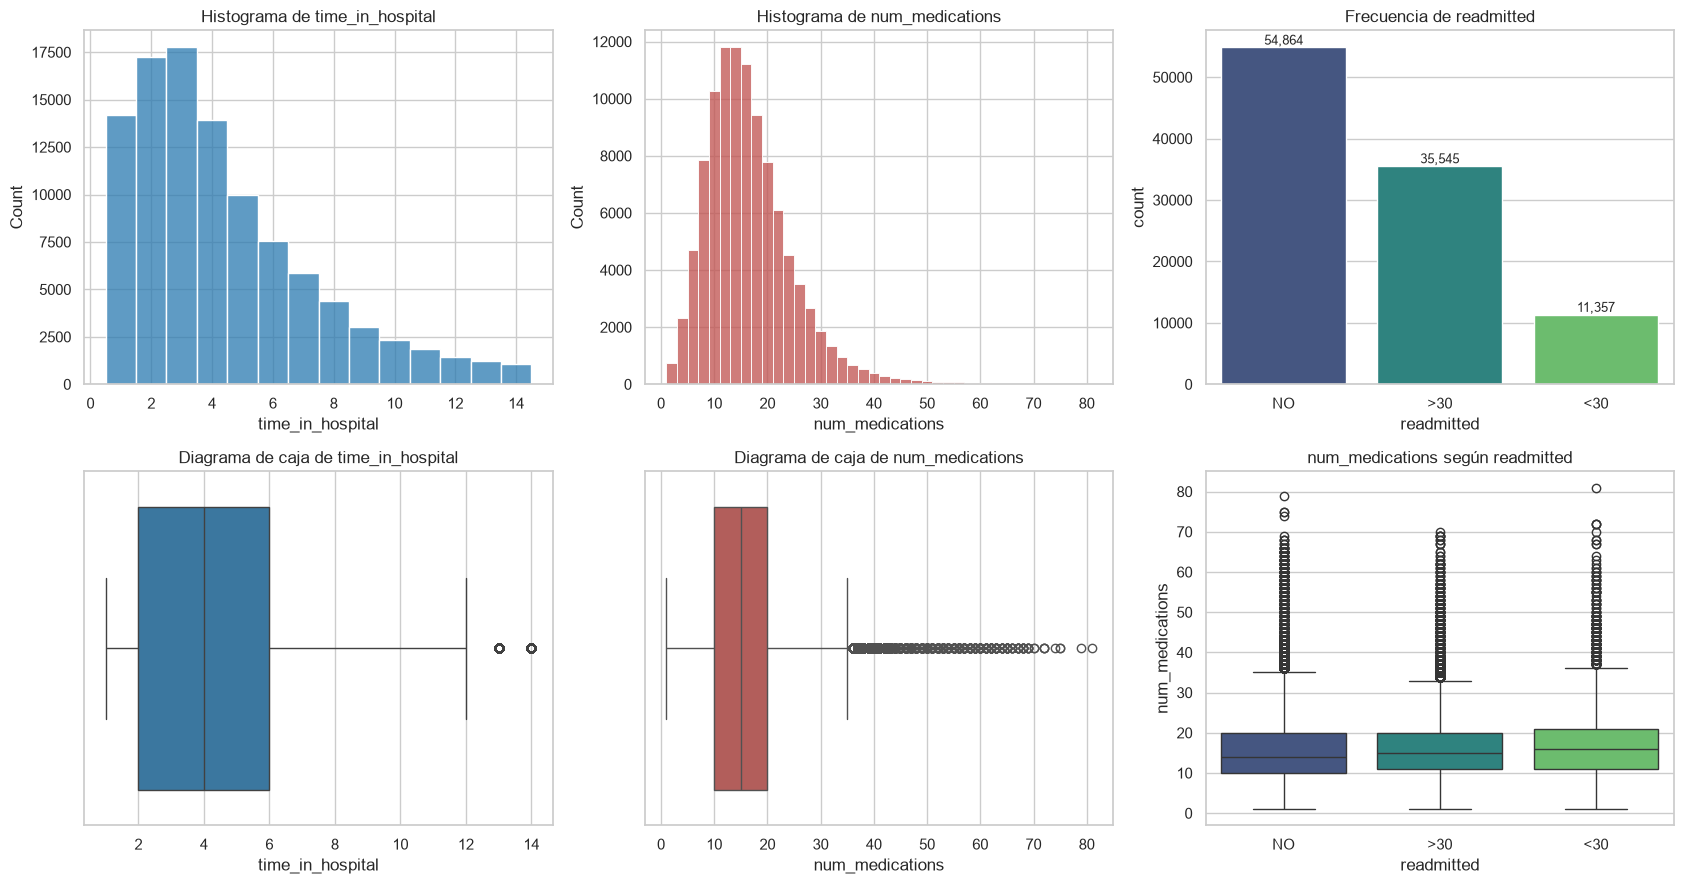

In [27]:
# Dos variables cuantitativas: una de escala media/simétrica y otra sesgada
V1, V2 = "time_in_hospital", "num_medications"
orden = ["NO", ">30", "<30"]

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
sns.histplot(df[V1], bins=14, discrete=True, ax=ax[0, 0], color="#2a7ab0"); ax[0, 0].set_title(f"Histograma de {V1}")
sns.histplot(df[V2], bins=40, ax=ax[0, 1], color="#c0504d");               ax[0, 1].set_title(f"Histograma de {V2}")
sns.countplot(x="readmitted", data=df, order=orden, ax=ax[0, 2], palette="viridis", hue="readmitted", legend=False)
ax[0, 2].set_title("Frecuencia de readmitted")
for p in ax[0, 2].patches:
    ax[0, 2].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                      ha="center", va="bottom", fontsize=9)
sns.boxplot(x=df[V1], ax=ax[1, 0], color="#2a7ab0"); ax[1, 0].set_title(f"Diagrama de caja de {V1}")
sns.boxplot(x=df[V2], ax=ax[1, 1], color="#c0504d"); ax[1, 1].set_title(f"Diagrama de caja de {V2}")
sns.boxplot(x="readmitted", y=V2, data=df, order=orden, ax=ax[1, 2], palette="viridis", hue="readmitted", legend=False)
ax[1, 2].set_title(f"{V2} según readmitted")
plt.tight_layout(); plt.show()

### Explicación línea por línea: Visualizaciones

- `V1, V2 = "time_in_hospital", "num_medications"`: asigna dos variables: una simétrica (V1) y otra sesgada (V2).
- `orden = ["NO", ">30", "<30"]`: orden fijo en que se mostrarán las categorías de `readmitted`.
- `fig, ax = plt.subplots(2, 3, figsize=(17, 9))`: crea una figura con una cuadrícula de 2 filas × 3 columnas de ejes; `figsize` fija el tamaño en pulgadas (ancho 17, alto 9). `ax` es una matriz de ejes accesibles como `ax[fila, columna]`.
- `sns.histplot(df[V1], bins=14, discrete=True, ax=ax[0, 0], color="#2a7ab0")`: histograma de V1 en el eje superior izquierdo: `bins` es el número de barras, `discrete=True` centra una barra en cada valor entero, `color` usa un código hexadecimal.
- `ax[0, 0].set_title(f"Histograma de {V1}")`: pone título al gráfico (el `;` en la línea original permite escribir dos instrucciones en una línea).
- `sns.histplot(df[V2], bins=40, ax=ax[0, 1], color="#c0504d")`: histograma de V2 con 40 barras en el eje superior central.
- `sns.countplot(x="readmitted", data=df, order=orden, ax=ax[0, 2], palette="viridis", hue="readmitted", legend=False)`: gráfico de barras de conteos por categoría; `order` fija el orden, `palette` elige la paleta de colores *viridis*, `hue` colorea por categoría y `legend=False` oculta la leyenda.
- `ax[0, 2].set_title("Frecuencia de readmitted")`: título del gráfico de frecuencias.
- `for p in ax[0, 2].patches:`: recorre cada barra (`patches`) del gráfico de conteos.
- `ax[0, 2].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)`: escribe sobre cada barra su altura (conteo) con separador de miles; la posición `(x, y)` es el centro horizontal y el borde superior de la barra; `ha`/`va` alinean el texto horizontal y verticalmente; `fontsize` es el tamaño de letra.
- `sns.boxplot(x=df[V1], ax=ax[1, 0], color="#2a7ab0")`: diagrama de caja horizontal de V1 (mediana, cuartiles, bigotes y puntos atípicos).
- `sns.boxplot(x=df[V2], ax=ax[1, 1], color="#c0504d")`: diagrama de caja de V2.
- `sns.boxplot(x="readmitted", y=V2, data=df, order=orden, ax=ax[1, 2], palette="viridis", hue="readmitted", legend=False)`: diagrama de caja de V2 separado por categoría de readmisión, para comparar distribuciones entre grupos.
- `ax[1, 2].set_title(f"{V2} según readmitted")`: título del último gráfico.
- `plt.tight_layout(); plt.show()`: `tight_layout` ajusta los márgenes para que no se solapen títulos y ejes; `show()` renderiza la figura.

**Interpretación de cada gráfico.**
1. **Histograma de `time_in_hospital`:** distribución discreta; la estancia más frecuente es de 3 días (y 1–3 días concentran gran parte de los casos), con cola derecha hasta 14; la mayoría de las estancias es corta.
2. **Histograma de `num_medications`:** forma de campana con cola derecha larga (máx. 81); la mayoría usa entre 10 y 20 fármacos.
3. **Frecuencia de `readmitted`:** `NO` es la clase mayoritaria; `<30` la menor (desbalance).
4. **Caja de `time_in_hospital`:** mediana 4 y bigote superior en 12; los puntos a la derecha son estancias inusualmente largas.
5. **Caja de `num_medications`:** muchos puntos por encima de 35 (hospitalizaciones muy complejas).
6. **`num_medications` por `readmitted`:** las medianas son muy parecidas entre grupos; las diferencias son pequeñas, **no** permiten afirmar causalidad.

### 3.7 Valores atípicos con el criterio IQR

In [28]:
filas = []
for c in VARS:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    filas.append({"variable": c, "Q1": q1, "Q3": q3, "IQR": iqr, "límite_inf": lo, "límite_sup": hi,
                  "n_atípicos": n_out, "% atípicos": round(n_out / len(df) * 100, 2), "máximo": df[c].max()})
atipicos = pd.DataFrame(filas).set_index("variable")
display(atipicos)

,Q1,Q3,IQR,límite_inf,límite_sup,n_atípicos,% atípicos,máximo
variable,,,,,,,,
time_in_hospital,2.0,6.0,4.0,-4.0,12.0,2252,2.21,14
num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,143,0.14,132
num_procedures,0.0,2.0,2.0,-3.0,5.0,4954,4.87,6
num_medications,10.0,20.0,10.0,-5.0,35.0,2557,2.51,81
number_outpatient,0.0,0.0,0.0,0.0,0.0,16739,16.45,42
number_emergency,0.0,0.0,0.0,0.0,0.0,11383,11.19,76
number_inpatient,0.0,1.0,1.0,-1.5,2.5,7049,6.93,21


### Explicación línea por línea: Valores atípicos con el criterio IQR

- `filas = []`: lista vacía donde se acumulará un diccionario de resultados por variable.
- `for c in VARS:`: bucle que repite el cálculo para cada una de las 7 variables.
- `q1, q3 = df[c].quantile([0.25, 0.75])`: obtiene el primer y tercer cuartil y los asigna a dos variables.
- `iqr = q3 - q1`: rango intercuartílico (IQR): amplitud del 50 % central de los datos.
- `lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr`: límites de Tukey: se consideran atípicos los valores por debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR.
- `n_out = ((df[c] < lo) | (df[c] > hi)).sum()`: compara cada valor con ambos límites; `|` es el operador lógico *o* elemento a elemento; `sum()` cuenta los atípicos.
- `filas.append({"variable": c, ... "máximo": df[c].max()})`: `append` agrega a la lista un diccionario con cuartiles, IQR, límites, número de atípicos, porcentaje (`round(..., 2)`) y valor máximo de la variable.
- `atipicos = pd.DataFrame(filas).set_index("variable")`: convierte la lista de diccionarios en tabla y usa `variable` como índice.
- `display(atipicos)`: muestra el resumen de atípicos.

**Interpretación y decisión (conservar).** Todas las variables tienen valores fuera de los límites IQR, sobre todo `number_outpatient` (16.5 %), `number_emergency` (11.2 %) y `number_inpatient` (6.9 %). En estas últimas el Q1, Q3 y mediana son 0, así que el IQR es 0 y **cualquier visita > 0 queda marcada como "atípica"** aunque sea perfectamente plausible: el criterio IQR no aplica bien a conteos con muchísimos ceros.
En `time_in_hospital` (2.2 %) y `num_medications` (2.5 %), los valores extremos (estancias de 12–14 días, 35–81 fármacos) son **clínicamente plausibles**: corresponden a pacientes graves y complejos. Por eso **se conservan todos**: eliminarlos solo por superar un umbral estadístico borraría justamente los casos más graves y reduciría el conjunto bajo 100 000 filas sin justificación clínica. Su efecto se trata en el escalamiento (Pasos 6 y 7).

# Paso 4. Fase 3 – Selección y limpieza

### Reglas explícitas de limpieza
| # | Regla | Justificación |
|---|---|---|
| R1 | Sustituir el marcador `?` por `NaN` (si existiera) | Uniformiza los faltantes (en esta versión ya vienen como `NaN`). |
| R2 | **No** tratar `None` de `max_glu_serum`/`A1Cresult` como dato perdido | Significa "prueba no realizada" (información válida). |
| R3 | No eliminar duplicados de `patient_nbr` | Son hospitalizaciones válidas distintas. |
| R4 | Eliminar solo filas totalmente duplicadas o con `encounter_id` repetido | No existen (0), se verifica. |
| R5 | Las 7 variables cuantitativas deben ser numéricas, sin nulos y **≥ 0** (conteos y días no pueden ser negativos; `time_in_hospital` ≥ 1) | Coherencia de dominio. |
| R6 | Conservar los valores atípicos | Plausibles clínicamente (ver 3.7). |
| R7 | Conservar `encounter_id` y `patient_nbr` como referencia, **excluidos** del escalamiento | Son identificadores. |
| R8 | No duplicar ni inventar registros para conservar el tamaño | Exigencia de trazabilidad. |

### Registro de cada decisión (filas y columnas antes y después)

In [29]:
registro_limpieza = []
def log(paso, regla, d_antes, d_despues, detalle=""):
    registro_limpieza.append({"paso": paso, "regla": regla,
        "filas_antes": d_antes.shape[0], "cols_antes": d_antes.shape[1],
        "filas_despues": d_despues.shape[0], "cols_despues": d_despues.shape[1],
        "filas_afectadas": d_antes.shape[0] - d_despues.shape[0], "detalle": detalle})

df_limpio = df_original.copy()

# R1: marcador "?" -> NaN (sin pérdida de filas)
antes = df_limpio
df_limpio = df_limpio.replace("?", np.nan)
log("1", "R1 '?' -> NaN", antes, df_limpio, f"marcadores '?' encontrados: {(antes.astype(str)=='?').sum().sum()}")

# R4: duplicados exactos y encounter_id repetidos
antes = df_limpio
df_limpio = df_limpio.drop_duplicates()
log("2", "R4 filas duplicadas exactas", antes, df_limpio, "ninguna fila duplicada")
antes = df_limpio
df_limpio = df_limpio.drop_duplicates(subset="encounter_id")
log("3", "R4 encounter_id repetido", antes, df_limpio, "ningún encounter_id repetido")

# R3: patient_nbr repetido -> se conserva (solo se registra)
log("4", "R3 patient_nbr repetido (se conserva)", df_limpio, df_limpio, f"{df_limpio['patient_nbr'].duplicated().sum():,} filas son reingresos del mismo paciente")

# R5: coherencia de dominio de las 7 variables
antes = df_limpio
df_limpio[VARS] = df_limpio[VARS].apply(pd.to_numeric, errors="coerce")
mask_ok = df_limpio[VARS].notna().all(axis=1) & (df_limpio[VARS] >= 0).all(axis=1) & (df_limpio["time_in_hospital"] >= 1)
df_limpio = df_limpio[mask_ok]
log("5", "R5 nulos/negativos en las 7 variables", antes, df_limpio, "ningún valor inválido")

# R6/R7: atípicos se conservan; selección de columnas de trabajo
log("6", "R6 atípicos IQR (se conservan)", df_limpio, df_limpio, "decisión justificada en 3.7")

resumen_limpieza = pd.DataFrame(registro_limpieza).set_index("paso")
display(resumen_limpieza)

# Comprobaciones finales
assert len(df_limpio) > 100_000
assert df_limpio[VARS].isna().sum().sum() == 0
assert (df_limpio[VARS] >= 0).all().all()
assert df_limpio["encounter_id"].is_unique
print(f"\nOK -> filas finales: {len(df_limpio):,} (> 100 000) | nulos en las 7 variables: {df_limpio[VARS].isna().sum().sum()}")

,regla,filas_antes,cols_antes,filas_despues,cols_despues,filas_afectadas,detalle
paso,,,,,,,
1,R1 '?' -> NaN,101766,50,101766,50,0,marcadores '?' encontrados: 0
2,R4 filas duplicadas exactas,101766,50,101766,50,0,ninguna fila duplicada
3,R4 encounter_id repetido,101766,50,101766,50,0,ningún encounter_id repetido
4,R3 patient_nbr repetido (se conserva),101766,50,101766,50,0,"30,248 filas son reingresos del mismo paciente"
5,R5 nulos/negativos en las 7 variables,101766,50,101766,50,0,ningún valor inválido
6,R6 atípicos IQR (se conservan),101766,50,101766,50,0,decisión justificada en 3.7



OK -> filas finales: 101,766 (> 100 000) | nulos en las 7 variables: 0


### Explicación línea por línea: Limpieza de datos con registro de reglas


**Función de registro**

- `registro_limpieza = []`: lista que almacenará la bitácora de cada regla aplicada.
- `def log(paso, regla, d_antes, d_despues, detalle=""):`: define una función que recibe el número de paso, el nombre de la regla, el DataFrame antes y después, y un detalle opcional (valor por defecto vacío).
- `registro_limpieza.append({...})`: añade a la bitácora un diccionario con filas y columnas antes/después y `filas_afectadas` (la diferencia entre ambas cantidades de filas).

**Reglas de limpieza**

- `df_limpio = df_original.copy()`: parte de una copia de la copia original, así la fuente nunca se modifica.
- `antes = df_limpio`: guarda una referencia al estado previo para compararlo con el posterior.
- `df_limpio = df_limpio.replace("?", np.nan)`: **R1**: reemplaza el marcador "?" por `np.nan` (valor faltante estándar de pandas).
- `log("1", "R1 ...", antes, df_limpio, f"marcadores ... {(antes.astype(str)=='?').sum().sum()}")`: registra la regla; el doble `sum()` suma primero por columna y luego el total general.
- `df_limpio = df_limpio.drop_duplicates()`: **R4**: elimina filas totalmente idénticas, conservando la primera.
- `df_limpio = df_limpio.drop_duplicates(subset="encounter_id")`: elimina filas con `encounter_id` repetido (`subset` indica la columna que se revisa).
- `log("4", "R3 patient_nbr repetido (se conserva)", df_limpio, df_limpio, ...)`: **R3**: solo registra cuántas filas son reingresos del mismo paciente (`duplicated().sum()`); no elimina nada porque cada hospitalización es válida.
- `df_limpio[VARS] = df_limpio[VARS].apply(pd.to_numeric, errors="coerce")`: **R5**: convierte las 7 columnas a número; `apply` aplica la función a cada columna y `errors="coerce"` transforma lo no convertible en NaN.
- `mask_ok = df_limpio[VARS].notna().all(axis=1) & (df_limpio[VARS] >= 0).all(axis=1) & (df_limpio["time_in_hospital"] >= 1)`: construye una *máscara booleana*: `notna()` indica valores no nulos, `all(axis=1)` exige que se cumpla en toda la fila, `&` es el *y* lógico elemento a elemento; se pide además que ningún valor sea negativo y que la estancia sea de al menos 1 día.
- `df_limpio = df_limpio[mask_ok]`: conserva solo las filas donde la máscara es True.
- `log("5", ...)`: registra la regla R5.
- `log("6", "R6 atípicos IQR (se conservan)", ...)`: **R6**: deja constancia de que los atípicos se conservan (decisión justificada en 3.7).

**Resumen y comprobaciones finales**

- `resumen_limpieza = pd.DataFrame(registro_limpieza).set_index("paso")`: convierte la bitácora en tabla indexada por paso.
- `display(resumen_limpieza)`: muestra la bitácora.
- `assert len(df_limpio) > 100_000`: comprueba que se mantengan más de 100 000 filas.
- `assert df_limpio[VARS].isna().sum().sum() == 0`: comprueba que no queden nulos en las 7 variables.
- `assert (df_limpio[VARS] >= 0).all().all()`: comprueba que todos los valores sean no negativos (`all().all()` reduce primero por columna y luego en total).
- `assert df_limpio["encounter_id"].is_unique`: comprueba que `encounter_id` no tenga repetidos.
- `print(f"\nOK -> filas finales: {len(df_limpio):,} ...")`: imprime un salto de línea (`\n`) y el resumen de verificación.

**Interpretación.** Ninguna regla eliminó filas: el conjunto limpio conserva las **101 766** hospitalizaciones y todas las columnas. Esto es coherente con los hallazgos del Paso 3 (sin duplicados, sin nulos ni negativos en las variables cuantitativas). No se duplicó ni inventó ningún registro.

In [30]:
# Copia de las variables numéricas limpias ANTES de transformar (con índice de referencia + identificadores)
num_limpias = df_limpio[VARS].copy()
num_limpias.index.name = "idx_original"
ids_referencia = df_limpio[["encounter_id", "patient_nbr"]].copy()   # solo referencia, no se escalan
num_limpias.to_csv("variables_numericas_limpias.csv")
print("Copia de variables limpias:", num_limpias.shape)
display(num_limpias.head())

Copia de variables limpias: (101766, 7)


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
idx_original,,,,,,,
0,1,41,0,1,0,0,0
1,3,59,0,18,0,0,0
2,2,11,5,13,2,0,1
3,2,44,1,16,0,0,0
4,1,51,0,8,0,0,0


### Explicación línea por línea: Copia de variables numéricas limpias

- `num_limpias = df_limpio[VARS].copy()`: selecciona solo las 7 columnas de trabajo y las copia de forma independiente.
- `num_limpias.index.name = "idx_original"`: nombra el índice para que, al exportar, quede como columna de referencia a la fila original.
- `ids_referencia = df_limpio[["encounter_id", "patient_nbr"]].copy()`: guarda aparte los identificadores (doble corchete = varias columnas); no se escalarán, solo sirven de referencia.
- `num_limpias.to_csv("variables_numericas_limpias.csv")`: exporta la copia limpia a CSV antes de transformarla (aquí sí se escribe el índice).
- `print("Copia de variables limpias:", num_limpias.shape)`: imprime las dimensiones de la copia.
- `display(num_limpias.head())`: muestra las primeras 5 filas.

# Paso 5. Selección de variables cuantitativas

Se utilizan las **siete variables** indicadas. Se verifica su significado y tipo con el diccionario oficial de UCI antes de transformarlas.

In [31]:
sel = dataset.variables[dataset.variables["name"].isin(VARS)][["name", "type", "description"]].set_index("name").loc[VARS]
sel["dtype_en_df"] = df_limpio[VARS].dtypes.astype(str)
with pd.option_context("display.max_colwidth", 120):
    display(sel)

excluidas = {
    "encounter_id": "identificador", "patient_nbr": "identificador",
    "admission_type_id": "código de categoría", "discharge_disposition_id": "código de categoría",
    "admission_source_id": "código de categoría", "age": "intervalos (no es edad continua)",
}
display(pd.Series(excluidas, name="motivo de exclusión del escalamiento").to_frame())


,type,description,dtype_en_df
name,,,
time_in_hospital,Integer,Integer number of days between admission and discharge,int64
num_lab_procedures,Integer,Number of lab tests performed during the encounter,int64
num_procedures,Integer,Number of procedures (other than lab tests) performed during the encounter,int64
num_medications,Integer,Number of distinct generic names administered during the encounter,int64
number_outpatient,Integer,Number of outpatient visits of the patient in the year preceding the encounter,int64
number_emergency,Integer,Number of emergency visits of the patient in the year preceding the encounter,int64
number_inpatient,Integer,Number of inpatient visits of the patient in the year preceding the encounter,int64


,motivo de exclusión del escalamiento
encounter_id,identificador
patient_nbr,identificador
admission_type_id,código de categoría
discharge_disposition_id,código de categoría
admission_source_id,código de categoría
age,intervalos (no es edad continua)


### Explicación línea por línea: Selección de variables cuantitativas

- `sel = dataset.variables[dataset.variables["name"].isin(VARS)][["name", "type", "description"]].set_index("name").loc[VARS]`: filtra los metadatos con `isin(VARS)` (True si el nombre está en la lista), conserva las columnas nombre, tipo y descripción, indexa por nombre y `.loc[VARS]` reordena según el orden de `VARS`.
- `sel["dtype_en_df"] = df_limpio[VARS].dtypes.astype(str)`: añade el tipo de dato real que tiene cada columna en el DataFrame limpio.
- `with pd.option_context("display.max_colwidth", 120):`: amplía temporalmente el ancho de texto por celda a 120 caracteres.
- `display(sel)`: muestra la tabla de selección.
- `excluidas = {...}`: diccionario con las columnas que NO se escalan y el motivo (identificadores, códigos de categoría y `age` en intervalos).
- `display(pd.Series(excluidas, name="motivo de exclusión del escalamiento").to_frame())`: convierte el diccionario en una Series con nombre y luego en tabla para mostrarla.

**Interpretación.** Las siete variables son enteros que representan **días o conteos** (cuantitativas discretas), por lo que tiene sentido compararlas en una escala común. Se excluyen los dos identificadores, los tres _id que son categorías codificadas con números y age, que viene en intervalos de 10 años y no es una edad continua.

# Paso 6. Normalización Min-Max

Se aplica `MinMaxScaler` con rango $[0,1]$ sobre **una copia** de las siete variables limpias, conservando nombres de columna e índice.

$$x_{norm}=\frac{x-x_{min}}{x_{max}-x_{min}}$$

In [32]:
X_minmax_in = num_limpias.copy()

mm = MinMaxScaler(feature_range=(0, 1))
X_norm = pd.DataFrame(mm.fit_transform(X_minmax_in), columns=VARS, index=X_minmax_in.index)

print("Primeras 10 filas normalizadas:")
display(X_norm.head(10).round(4))

tabla_mm = pd.DataFrame({
    "min_antes": X_minmax_in.min(), "max_antes": X_minmax_in.max(),
    "min_después": X_norm.min(), "max_después": X_norm.max(),
})
display(tabla_mm)

# Comprobación del rango con tolerancia numérica
assert np.allclose(X_norm.min(), 0, atol=1e-12) and np.allclose(X_norm.max(), 1, atol=1e-12)
assert (X_norm.index == X_minmax_in.index).all() and list(X_norm.columns) == VARS
print("OK: rango [0, 1] verificado con tolerancia 1e-12; mismo índice y nombres de columnas.")

Primeras 10 filas normalizadas:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
idx_original,,,,,,,
0,0.0000,0.3053,0.0000,0.0000,0.0000,0.0,0.0000
1,0.1538,0.4427,0.0000,0.2125,0.0000,0.0,0.0000
2,0.0769,0.0763,0.8333,0.1500,0.0476,0.0,0.0476
3,0.0769,0.3282,0.1667,0.1875,0.0000,0.0,0.0000
4,0.0000,0.3817,0.0000,0.0875,0.0000,0.0,0.0000
5,0.1538,0.2290,1.0000,0.1875,0.0000,0.0,0.0000
6,0.2308,0.5267,0.1667,0.2500,0.0000,0.0,0.0000
7,0.3077,0.5496,0.0000,0.1375,0.0000,0.0,0.0000
8,0.9231,0.5115,0.3333,0.3375,0.0000,0.0,0.0000


,min_antes,max_antes,min_después,max_después
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0


OK: rango [0, 1] verificado con tolerancia 1e-12; mismo índice y nombres de columnas.


### Explicación línea por línea: Normalización Min-Max

- `X_minmax_in = num_limpias.copy()`: copia de entrada para esta transformación (así no se altera `num_limpias`).
- `mm = MinMaxScaler(feature_range=(0, 1))`: crea el escalador; `feature_range=(0, 1)` define el rango destino. Fórmula: x' = (x − mín) / (máx − mín).
- `X_norm = pd.DataFrame(mm.fit_transform(X_minmax_in), columns=VARS, index=X_minmax_in.index)`: `fit_transform` aprende el mínimo y máximo de cada columna (`fit`) y las transforma (`transform`) devolviendo una matriz NumPy; `pd.DataFrame(..., columns, index)` la vuelve tabla conservando nombres de columnas e índice originales.
- `print("Primeras 10 filas normalizadas:")`: texto de encabezado.
- `display(X_norm.head(10).round(4))`: muestra 10 filas con 4 decimales.
- `tabla_mm = pd.DataFrame({...})`: tabla de verificación con mínimo y máximo de cada variable antes y después de normalizar.
- `assert np.allclose(X_norm.min(), 0, atol=1e-12) and np.allclose(X_norm.max(), 1, atol=1e-12)`: `np.allclose` compara con tolerancia numérica (`atol` = tolerancia absoluta): comprueba que los mínimos sean 0 y los máximos 1.
- `assert (X_norm.index == X_minmax_in.index).all() and list(X_norm.columns) == VARS`: comprueba que el índice y el orden de columnas no cambiaron.
- `print("OK: ...")`: mensaje de confirmación si todas las aserciones pasaron.

**Influencia de los valores extremos.** Min-Max usa **solo el mínimo y el máximo**, así que un único valor extremo estira el denominador y comprime al resto. Ejemplo real: `number_emergency` llega a 76, de modo que casi todos sus valores (0, 1, 2…) quedan aplastados entre 0 y ~0.03; igual con `number_outpatient` (máx. 42). En cambio `num_lab_procedures` (máx. 132, pero con distribución más pareja) se reparte mejor en [0, 1]. Min-Max **no elimina** los atípicos: solo cambia la escala.

**Columna constante (denominador cero).** Si una variable tuviera $x_{max}=x_{min}$, la fórmula divide entre 0. `MinMaxScaler` lo maneja asignándole escala 1 al denominador, de modo que el resultado es una columna de **ceros**. Se demuestra a continuación:

In [33]:
const = pd.DataFrame({"constante": [5, 5, 5, 5], "variable": [1, 2, 3, 4]})
print(MinMaxScaler().fit_transform(const))
print("\nscale_ usada para la columna constante:", MinMaxScaler().fit(const).scale_)
print("Las 7 variables elegidas NO son constantes:", (X_minmax_in.nunique() > 1).all())

[[0.         0.        ]
 [0.         0.33333333]
 [0.         0.66666667]
 [0.         1.        ]]

scale_ usada para la columna constante: [1.         0.33333333]
Las 7 variables elegidas NO son constantes: True


### Explicación línea por línea: Caso de columna constante en Min-Max

- `const = pd.DataFrame({"constante": [5, 5, 5, 5], "variable": [1, 2, 3, 4]})`: tabla de prueba con una columna constante (siempre 5) y otra variable.
- `print(MinMaxScaler().fit_transform(const))`: aplica Min-Max y muestra la matriz resultante; la constante no puede dividirse por cero (máx − mín = 0), y scikit-learn la deja en 0.
- `print("\nscale_ usada ...:", MinMaxScaler().fit(const).scale_)`: `scale_` es el factor de escala aprendido; para la constante scikit-learn lo sustituye por 1 para evitar la división entre cero.
- `print("Las 7 variables elegidas NO son constantes:", (X_minmax_in.nunique() > 1).all())`: verifica que cada variable real tenga más de un valor distinto (`all()` = todas cumplen).

# Paso 7. Estandarización Z-score

Se aplica `StandardScaler` sobre **otra copia** de las variables numéricas limpias originales (**no** sobre el resultado de Min-Max).

$$z=\frac{x-\mu}{\sigma}$$

con $\mu$ la media y $\sigma$ la desviación estándar poblacional (`ddof=0`) de la variable usada para ajustar el escalador.

In [34]:
X_std_in = num_limpias.copy()        # parte de los datos limpios originales, NO de X_norm

ss = StandardScaler()
X_est = pd.DataFrame(ss.fit_transform(X_std_in), columns=VARS, index=X_std_in.index)

print("Primeras 10 filas estandarizadas:")
display(X_est.head(10).round(4))

tabla_z = pd.DataFrame({"media": X_est.mean(), "desv_est (ddof=0)": X_est.std(ddof=0),
                        "mín": X_est.min(), "máx": X_est.max()})
display(tabla_z)

# Comprobaciones con tolerancia
assert np.allclose(X_est.mean(), 0, atol=1e-9)
assert np.allclose(X_est.std(ddof=0), 1, atol=1e-9)
print("OK: media ≈ 0 y desviación (ddof=0) ≈ 1 con tolerancia 1e-9.")

Primeras 10 filas estandarizadas:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
idx_original,,,,,,,
0,-1.1376,-0.1065,-0.7854,-1.8483,-0.2915,-0.2126,-0.5033
1,-0.4677,0.8084,-0.7854,0.2434,-0.2915,-0.2126,-0.5033
2,-0.8027,-1.6314,2.1458,-0.3718,1.2867,-0.2126,0.2886
3,-0.8027,0.0460,-0.1992,-0.0027,-0.2915,-0.2126,-0.5033
4,-1.1376,0.4018,-0.7854,-0.9870,-0.2915,-0.2126,-0.5033
5,-0.4677,-0.6148,2.7320,-0.0027,-0.2915,-0.2126,-0.5033
6,-0.1327,1.3675,-0.1992,0.6125,-0.2915,-0.2126,-0.5033
7,0.2023,1.5200,-0.7854,-0.4948,-0.2915,-0.2126,-0.5033
8,2.8823,1.2658,0.3871,1.4738,-0.2915,-0.2126,-0.5033


,media,desv_est (ddof=0),mín,máx
time_in_hospital,5.809126e-17,1.0,-1.137649,3.217324
num_lab_procedures,1.161825e-16,1.0,-2.139630,4.518815
num_procedures,-6.479410e-17,1.0,-0.785398,2.732016
num_medications,-1.340568e-16,1.0,-1.848268,7.994826
number_outpatient,3.574847e-17,1.0,-0.291461,32.850938
number_emergency,1.787424e-17,1.0,-0.212620,81.466733
number_inpatient,-3.574847e-17,1.0,-0.503276,16.125684


OK: media ≈ 0 y desviación (ddof=0) ≈ 1 con tolerancia 1e-9.


### Explicación línea por línea: Estandarización Z-score

- `X_std_in = num_limpias.copy()`: nueva copia partiendo de los datos limpios (no de `X_norm`) para no encadenar transformaciones.
- `ss = StandardScaler()`: crea el estandarizador. Fórmula: z = (x − μ) / σ, con μ la media y σ la desviación estándar.
- `X_est = pd.DataFrame(ss.fit_transform(X_std_in), columns=VARS, index=X_std_in.index)`: calcula μ y σ por columna, transforma los datos y reconstruye el DataFrame con los mismos nombres e índice.
- `print("Primeras 10 filas estandarizadas:")`: encabezado.
- `display(X_est.head(10).round(4))`: muestra 10 filas con 4 decimales.
- `tabla_z = pd.DataFrame({"media": X_est.mean(), "desv_est (ddof=0)": X_est.std(ddof=0), ...})`: tabla de verificación: `ddof=0` usa el divisor N (desviación poblacional, igual que scikit-learn) en lugar de N−1.
- `assert np.allclose(X_est.mean(), 0, atol=1e-9)`: comprueba que las medias sean ≈ 0.
- `assert np.allclose(X_est.std(ddof=0), 1, atol=1e-9)`: comprueba que las desviaciones sean ≈ 1.
- `print("OK: ...")`: mensaje de confirmación.

¿Por qué hay valores negativos y fuera de [0, 1]? Z-score centra la variable en su media y la mide en desviaciones estándar. Los valores por debajo de la media dan z < 0 y los muy por encima dan z > 1; no existe un tope fijo. Por ejemplo, un number_emergency de 76 obtiene z ≈ 81, es decir, más de 80 desviaciones por encima de la media (ver tabla anterior). Z-score no acota a un intervalo; sí deja todas las variables con media 0 y desviación 1.

Columnas constantes. Si σ = 0, StandardScaler evita dividir por cero (usa escala 1) y devuelve una columna de ceros con desviación resultante 0:

In [35]:
sc = StandardScaler().fit(const)
print(sc.transform(const))
print("\nDesviación de la columna constante tras escalar:", sc.transform(const)[:, 0].std())


[[ 0.         -1.34164079]
 [ 0.         -0.4472136 ]
 [ 0.          0.4472136 ]
 [ 0.          1.34164079]]

Desviación de la columna constante tras escalar: 0.0


### Explicación línea por línea: Caso de columna constante en Z-score

- `sc = StandardScaler().fit(const)`: ajusta el estandarizador a la tabla de prueba con columna constante (σ = 0).
- `print(sc.transform(const))`: transforma y muestra; la columna constante da 0 porque scikit-learn reemplaza σ = 0 por 1 y evita dividir entre cero.
- `print("\nDesviación ...:", sc.transform(const)[:, 0].std())`: `[:, 0]` toma todas las filas de la primera columna; `std()` calcula su desviación, que resulta 0.

**Nota metodológica.** En esta práctica descriptiva los escaladores se ajustan sobre todos los datos analizados. Si después se construyera un modelo, habría que **separar primero entrenamiento y prueba** (evitando que un mismo paciente quede en ambas particiones), **ajustar el escalador solo con el entrenamiento** y solo *transformar* los demás subconjuntos con esos parámetros, para evitar fuga de información.

---
# Paso 8. Comparación y exportación

### 8.1 Tabla comparativa: original limpio vs. normalizado vs. estandarizado

In [36]:
def estad(X, nombre):
    t = pd.DataFrame({"mín": X.min(), "máx": X.max(), "media": X.mean(), "desv_est": X.std(ddof=0)})
    t.columns = pd.MultiIndex.from_product([[nombre], t.columns])
    return t

comparacion = pd.concat([estad(num_limpias, "1. Original limpio"),
                         estad(X_norm, "2. Normalizado (Min-Max)"),
                         estad(X_est, "3. Estandarizado (Z-score)")], axis=1)
display(comparacion.round(4))
comparacion.round(6).to_csv("tabla_comparacion_estadistica.csv")

1. Original limpio                        2. Normalizado (Min-Max)                       3. Estandarizado (Z-score)                        
                                  mín  máx    media desv_est                      mín  máx   media desv_est                        mín      máx media desv_est
time_in_hospital                    1   14   4.3960   2.9851                      0.0  1.0  0.2612   0.2296                    -1.1376   3.2173   0.0      1.0
num_lab_procedures                  1  132  43.0956  19.6743                      0.0  1.0  0.3213   0.1502                    -2.1396   4.5188   0.0      1.0
num_procedures                      0    6   1.3397   1.7058                      0.0  1.0  0.2233   0.2843                    -0.7854   2.7320  -0.0      1.0
num_medications                     1   81  16.0218   8.1275                      0.0  1.0  0.1878   0.1016                    -1.8483   7.9948  -0.0      1.0
number_outpatient                   0   42   0.3694   1.2673                      0.0  1.0  0.0088   0.0302                    -0.2915  32.8509   0.0      1.0
number_emergency                    0   76   0.1978   0.9305                      0.0  1.0  0.0026   0.0122                    -0.2126  81.4667   0.0      1.0
number_inpatient                    0   21   0.6356   1.2629                      0.0  1.0  0.0303   0.0601                    -0.5033  16.1257  -0.0      1.0

### Explicación línea por línea: Tabla comparativa de las tres versiones

- `def estad(X, nombre):`: función que resume una tabla `X` y etiqueta el resultado con `nombre`.
- `t = pd.DataFrame({"mín": X.min(), "máx": X.max(), "media": X.mean(), "desv_est": X.std(ddof=0)})`: calcula mínimo, máximo, media y desviación poblacional por variable.
- `t.columns = pd.MultiIndex.from_product([[nombre], t.columns])`: crea columnas de dos niveles (`MultiIndex`): el nivel superior es el nombre de la versión y el inferior el estadístico.
- `return t`: devuelve la tabla.
- `comparacion = pd.concat([estad(...), estad(...), estad(...)], axis=1)`: `concat` con `axis=1` une las tres tablas lado a lado (original, normalizado y estandarizado).
- `display(comparacion.round(4))`: muestra la comparación con 4 decimales.
- `comparacion.round(6).to_csv("tabla_comparacion_estadistica.csv")`: exporta la tabla con 6 decimales a CSV.

**Interpretación.** Las columnas originales tienen escalas muy diferentes (medias de 0.2 a 43; desviaciones de 0.9 a 19.7). Con Min-Max, todas quedan en [0, 1] pero con medias y desviaciones distintas (las muy sesgadas quedan con media cercana a 0). Con Z-score, todas tienen media 0 y desviación 1, pero mínimos y máximos distintos según la forma de cada variable.

### 8.2 Gráficos comparables de las tres versiones (dos variables)

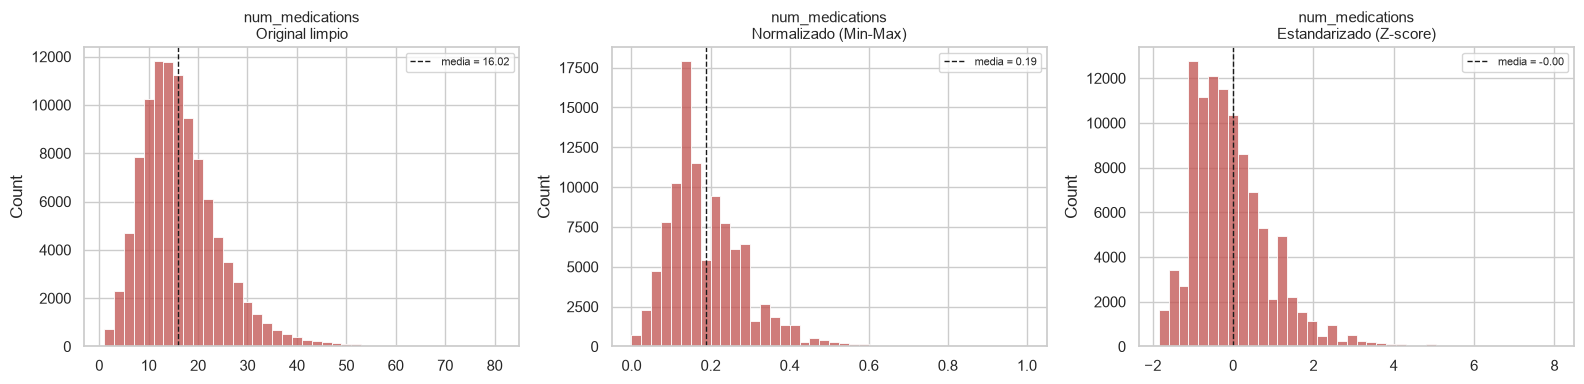

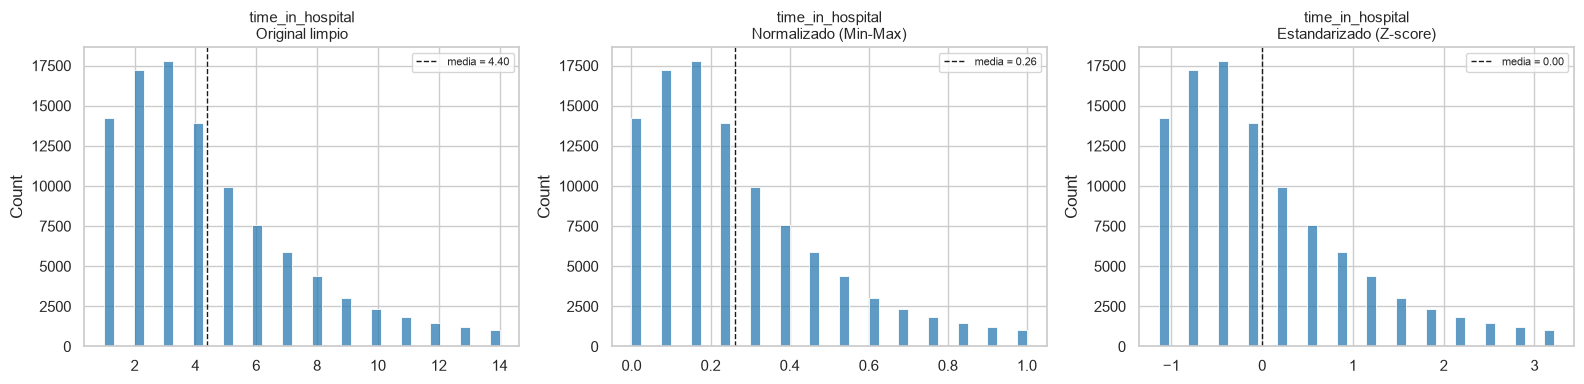

Asimetría (skew) por versión:


,original,min-max,z-score
num_medications,1.326672,1.326672,1.326672
time_in_hospital,1.133999,1.133999,1.133999


In [37]:
def comparar(var, color):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for a, (serie, tit) in zip(ax, [(num_limpias[var], "Original limpio"),
                                    (X_norm[var], "Normalizado (Min-Max)"),
                                    (X_est[var], "Estandarizado (Z-score)")]):
        sns.histplot(serie, bins=40, ax=a, color=color)
        a.set_title(f"{var}\n{tit}", fontsize=11); a.set_xlabel("")
        a.axvline(serie.mean(), color="k", ls="--", lw=1, label=f"media = {serie.mean():.2f}")
        a.legend(fontsize=8)
    plt.tight_layout(); plt.show()

comparar("num_medications", "#c0504d")
comparar("time_in_hospital", "#2a7ab0")

# La forma se conserva: la asimetría (skew) es idéntica en las tres versiones
print("Asimetría (skew) por versión:")
display(pd.DataFrame({"original": num_limpias[["num_medications","time_in_hospital"]].skew(),
                      "min-max": X_norm[["num_medications","time_in_hospital"]].skew(),
                      "z-score": X_est[["num_medications","time_in_hospital"]].skew()}).round(6))

### Explicación línea por línea: Gráficos comparables de las tres versiones

- `def comparar(var, color):`: función que dibuja la variable `var` en sus tres versiones con un color dado.
- `fig, ax = plt.subplots(1, 3, figsize=(16, 4))`: una fila de tres gráficos de 16×4 pulgadas.
- `for a, (serie, tit) in zip(ax, [(...), (...), (...)]):`: `zip` empareja cada eje con una tupla (serie de datos, título); el bucle dibuja los tres paneles.
- `sns.histplot(serie, bins=40, ax=a, color=color)`: histograma de 40 barras en el eje actual.
- `a.set_title(f"{var}\n{tit}", fontsize=11); a.set_xlabel("")`: título de dos líneas (`\n` = salto de línea) y se borra la etiqueta del eje X.
- `a.axvline(serie.mean(), color="k", ls="--", lw=1, label=f"media = {serie.mean():.2f}")`: traza una línea vertical en la media: `color="k"` negro, `ls` estilo de línea discontinuo, `lw` grosor, `label` texto de la leyenda.
- `a.legend(fontsize=8)`: muestra la leyenda con letra pequeña.
- `plt.tight_layout(); plt.show()`: ajusta márgenes y muestra la figura.
- `comparar("num_medications", "#c0504d")`: llama a la función con la variable sesgada.
- `comparar("time_in_hospital", "#2a7ab0")`: llama a la función con la variable más simétrica.
- `print("Asimetría (skew) por versión:")`: encabezado.
- `display(pd.DataFrame({"original": ...skew(), "min-max": ...skew(), "z-score": ...skew()}).round(6))`: calcula el coeficiente de asimetría de dos variables en cada versión y las muestra con 6 decimales; resultan iguales porque el escalamiento lineal no cambia la forma de la distribución.

**Interpretación.** Los tres histogramas tienen **exactamente la misma forma**; solo cambian los valores del eje X: [1, 81] → [0, 1] → centrado en 0 con unidad de desviación. Esto ocurre porque ambas transformaciones son **lineales** ($y = ax + b$): modifican origen y escala, pero conservan el orden, las proporciones entre distancias y, por tanto, la **asimetría** (la tabla muestra el mismo `skew` en las tres versiones). Cambiar de escala **no** corrige una distribución sesgada; para eso se necesitarían transformaciones no lineales (log, raíz, Box-Cox).

### 8.3 Demostración manual con cinco valores

In [38]:
var = "num_medications"
rng = np.random.default_rng(42)
cinco_pos = rng.choice(len(num_limpias), size=5, replace=False)       # cinco filas al azar (reproducible)
cinco = num_limpias.iloc[cinco_pos][var]

x_min, x_max = num_limpias[var].min(), num_limpias[var].max()
mu, sigma = num_limpias[var].mean(), num_limpias[var].std(ddof=0)
print(f"Variable: {var}")
print(f"Parámetros -> x_min = {x_min}, x_max = {x_max}, μ = {mu:.6f}, σ (ddof=0) = {sigma:.6f}\n")

manual = pd.DataFrame({"x": cinco})
manual["minmax_manual"] = (manual["x"] - x_min) / (x_max - x_min)
manual["minmax_sklearn"] = X_norm.loc[cinco.index, var]
manual["z_manual"] = (manual["x"] - mu) / sigma
manual["z_sklearn"] = X_est.loc[cinco.index, var]
display(manual.round(6))

# Detalle de cada cálculo
for i, x in cinco.items():
    print(f"fila {i}: x={x}  ->  MinMax = ({x}-{x_min})/({x_max}-{x_min}) = {(x-x_min)/(x_max-x_min):.6f}"
          f"   |   Z = ({x}-{mu:.4f})/{sigma:.4f} = {(x-mu)/sigma:.6f}")

assert np.allclose(manual["minmax_manual"], manual["minmax_sklearn"])
assert np.allclose(manual["z_manual"], manual["z_sklearn"])
print("\nOK: los cálculos manuales coinciden con scikit-learn.")

Variable: num_medications
Parámetros -> x_min = 1, x_max = 81, μ = 16.021844, σ (ddof=0) = 8.127526



,x,minmax_manual,minmax_sklearn,z_manual,z_sklearn
idx_original,,,,,
78760,24,0.2875,0.2875,0.981622,0.981622
44662,9,0.1000,0.1000,-0.863958,-0.863958
66611,17,0.2000,0.2000,0.120351,0.120351
9082,15,0.1750,0.1750,-0.125726,-0.125726
44066,10,0.1125,0.1125,-0.740920,-0.740920


fila 78760: x=24  ->  MinMax = (24-1)/(81-1) = 0.287500   |   Z = (24-16.0218)/8.1275 = 0.981622
fila 44662: x=9  ->  MinMax = (9-1)/(81-1) = 0.100000   |   Z = (9-16.0218)/8.1275 = -0.863958
fila 66611: x=17  ->  MinMax = (17-1)/(81-1) = 0.200000   |   Z = (17-16.0218)/8.1275 = 0.120351
fila 9082: x=15  ->  MinMax = (15-1)/(81-1) = 0.175000   |   Z = (15-16.0218)/8.1275 = -0.125726
fila 44066: x=10  ->  MinMax = (10-1)/(81-1) = 0.112500   |   Z = (10-16.0218)/8.1275 = -0.740920

OK: los cálculos manuales coinciden con scikit-learn.


### Explicación línea por línea: Demostración manual con cinco valores

- `var = "num_medications"`: variable elegida para la demostración.
- `rng = np.random.default_rng(42)`: crea un generador de números aleatorios con *semilla* 42, lo que hace el sorteo reproducible.
- `cinco_pos = rng.choice(len(num_limpias), size=5, replace=False)`: elige 5 posiciones al azar entre todas las filas; `replace=False` evita repetir posiciones.
- `cinco = num_limpias.iloc[cinco_pos][var]`: `iloc` selecciona filas por posición numérica; luego se toma solo la columna `var`.
- `x_min, x_max = num_limpias[var].min(), num_limpias[var].max()`: mínimo y máximo de la variable (parámetros de Min-Max).
- `mu, sigma = num_limpias[var].mean(), num_limpias[var].std(ddof=0)`: media y desviación poblacional (parámetros de Z-score).
- `print(f"Variable: {var}")`: imprime la variable.
- `print(f"Parámetros -> x_min = ..., σ (ddof=0) = {sigma:.6f}\n")`: imprime los parámetros; `:.6f` formatea con 6 decimales.
- `manual = pd.DataFrame({"x": cinco})`: tabla con los 5 valores originales.
- `manual["minmax_manual"] = (manual["x"] - x_min) / (x_max - x_min)`: aplica la fórmula Min-Max a mano.
- `manual["minmax_sklearn"] = X_norm.loc[cinco.index, var]`: trae el valor normalizado por scikit-learn (`loc` selecciona por etiqueta de índice).
- `manual["z_manual"] = (manual["x"] - mu) / sigma`: aplica la fórmula Z-score a mano.
- `manual["z_sklearn"] = X_est.loc[cinco.index, var]`: trae el valor estandarizado por scikit-learn.
- `display(manual.round(6))`: muestra la comparación manual vs. scikit-learn.
- `for i, x in cinco.items():`: recorre cada pareja (índice, valor) de la Serie.
- `print(f"fila {i}: x={x} -> MinMax = ({x}-{x_min})/({x_max}-{x_min}) = ... | Z = ... ")`: imprime el cálculo paso a paso de cada fórmula con los números sustituidos.
- `assert np.allclose(manual["minmax_manual"], manual["minmax_sklearn"])`: comprueba que ambos métodos de Min-Max coinciden.
- `assert np.allclose(manual["z_manual"], manual["z_sklearn"])`: comprueba lo mismo para Z-score.
- `print("\nOK: ...")`: mensaje de confirmación.

**Interpretación.** El cálculo manual con los parámetros del ajuste (mín, máx, media y σ) reproduce exactamente la salida de `MinMaxScaler` y `StandardScaler`: los escaladores solo aplican las fórmulas con parámetros aprendidos de los datos.

### 8.4 Exportación de los CSV con el mismo orden e índice de referencia

In [39]:
# Índice de referencia = posición/índice de la fila en el dataset original; se añade además encounter_id
X_norm_out = X_norm.copy();  X_est_out = X_est.copy()
for X in (X_norm_out, X_est_out):
    X.index.name = "idx_original"
    X.insert(0, "encounter_id", ids_referencia["encounter_id"].values)   # solo referencia (no escalada)

X_norm_out.to_csv("datos_normalizados.csv")
X_est_out.to_csv("datos_estandarizados.csv")

# Verificación de la exportación
n = pd.read_csv("datos_normalizados.csv", index_col="idx_original")
e = pd.read_csv("datos_estandarizados.csv", index_col="idx_original")
assert n.index.equals(e.index) and list(n.columns) == list(e.columns)
assert len(n) == len(e) == len(df_original) and (n["encounter_id"].values == df_original["encounter_id"].values).all()
assert np.allclose(n[VARS], X_norm) and np.allclose(e[VARS], X_est)
print("Archivos exportados: datos_normalizados.csv, datos_estandarizados.csv")
print("Filas:", len(n), "| columnas:", list(n.columns))
print("Mismo orden e índice en ambas versiones:", n.index.equals(e.index))
display(n.head(3)); display(e.head(3))

Archivos exportados: datos_normalizados.csv, datos_estandarizados.csv
Filas: 101766 | columnas: ['encounter_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient']
Mismo orden e índice en ambas versiones: True


,encounter_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
idx_original,,,,,,,,
0,2278392,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,149190,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,64410,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619


,encounter_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
idx_original,,,,,,,,
0,2278392,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,149190,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,64410,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579


### Explicación línea por línea: Exportación de los CSV

- `X_norm_out = X_norm.copy();  X_est_out = X_est.copy()`: copias de salida de ambas versiones (dos instrucciones separadas por `;`).
- `for X in (X_norm_out, X_est_out):`: recorre ambas tablas para aplicarles las mismas operaciones.
- `X.index.name = "idx_original"`: nombra el índice como referencia a la fila original.
- `X.insert(0, "encounter_id", ids_referencia["encounter_id"].values)`: `insert` agrega la columna `encounter_id` en la posición 0 (primera); `.values` pasa solo los valores para evitar alineación por índice. Es solo referencia, no está escalada.
- `X_norm_out.to_csv("datos_normalizados.csv")`: exporta la versión normalizada.
- `X_est_out.to_csv("datos_estandarizados.csv")`: exporta la versión estandarizada.
- `n = pd.read_csv("datos_normalizados.csv", index_col="idx_original")`: relee el CSV para verificar; `index_col` indica qué columna actúa como índice.
- `e = pd.read_csv("datos_estandarizados.csv", index_col="idx_original")`: relee el segundo archivo.
- `assert n.index.equals(e.index) and list(n.columns) == list(e.columns)`: comprueba que ambos archivos tengan el mismo índice y las mismas columnas en el mismo orden.
- `assert len(n) == len(e) == len(df_original) and (n["encounter_id"].values == df_original["encounter_id"].values).all()`: comprueba que ambos tengan tantas filas como el original y que los `encounter_id` coincidan fila a fila.
- `assert np.allclose(n[VARS], X_norm) and np.allclose(e[VARS], X_est)`: comprueba que los valores guardados coinciden con los calculados (sin pérdida por redondeo).
- `print("Archivos exportados: ...")`: informa los archivos creados.
- `print("Filas:", len(n), "| columnas:", list(n.columns))`: imprime el número de filas y los nombres de columnas.
- `print("Mismo orden e índice en ambas versiones:", n.index.equals(e.index))`: imprime el resultado de la verificación (True).
- `display(n.head(3)); display(e.head(3))`: muestra las 3 primeras filas de cada archivo.

**Correspondencia con los registros originales.** Ambos CSV tienen **101 766 filas en el mismo orden** que `hospitalizaciones_diabetes_original.csv`. La columna `idx_original` es el índice de la fila original (0 a 101 765) y `encounter_id` permite ubicar la hospitalización exacta; **no se escalan** (son solo referencia). Las siete columnas restantes son las variables transformadas.

---
# Conclusiones

**Respuesta a las preguntas de análisis**
1. **Distribuciones.** Las variables de hospitalización son conteos con asimetría positiva; los conteos de visitas previas (`number_outpatient`, `number_emergency`, `number_inpatient`) son extremadamente sesgados (mediana 0 y máximos de 21 a 76), mientras `num_lab_procedures` es la más simétrica y la de mayor escala.
2. **Readmisión.** ≈ 53.9 % `NO`, 34.9 % `>30` y 11.2 % `<30`. Descriptivamente, los grupos readmitidos muestran más visitas previas (p. ej. `number_inpatient` promedio ≈ 1.22 en `<30` frente a ≈ 0.38 en `NO`), pero las diferencias son descriptivas y **no implican causalidad**.
3. **Calidad.** Sin duplicados, sin nulos ni negativos en las siete variables; los faltantes se concentran en `weight`, `max_glu_serum`, `A1Cresult`, `medical_specialty` y `payer_code`, y en las pruebas `None` significa "no realizada". Los atípicos son clínicamente plausibles y se conservaron. Se mantuvieron las 101 766 filas.

**Criterios de éxito:** se cumplieron los cuatro (filas > 100 000; sin nulos y mismo orden en ambos CSV; rangos/medias/desviaciones verificados con tolerancias; cálculo manual = scikit-learn).

**¿Cuándo usar cada transformación?**
- **Min-Max** cuando se necesita un rango acotado [0, 1] (p. ej. redes neuronales, algunos algoritmos basados en distancia o visualización) y no hay valores extremos dominantes; es muy sensible a ellos.
- **Z-score** cuando interesa comparar en unidades de desviación, para métodos que suponen datos centrados (regresión regularizada, PCA, SVM, k-means) y cuando hay atípicos moderados; no acota el rango.
- Con datos muy sesgados y colas largas, ninguna de las dos las "corrige": conviene además una transformación no lineal (log) o un escalador robusto (mediana/IQR).

**Limitaciones**
- Datos de 1999–2008 y de hospitales de EE. UU.; poblaciones y prácticas actuales pueden diferir.
- Filas no independientes (mismo paciente en varias hospitalizaciones).
- Los escaladores se ajustaron con todo el conjunto (válido para esta práctica descriptiva, pero causaría fuga de información si se usaran antes de dividir en train/test).
- Solo se analizaron siete variables cuantitativas; no se entrenó ni evaluó ningún modelo.

**Fuente:** Clore, J., Cios, K., DeShazo, J., y Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008*. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J. Documentación técnica: [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html) · [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

# Diccionario de vocabulario técnico

Términos técnicos utilizados en el código y en las explicaciones de este cuaderno, en orden alfabético.

| Término | Definición |
|---|---|
| **Aserción (`assert`)** | Instrucción que comprueba que una condición sea verdadera; si no lo es, detiene el programa con un error. Sirve para validar supuestos. |
| **Asimetría (*skewness*)** | Medida de la falta de simetría de una distribución. Positiva: cola larga a la derecha; negativa: a la izquierda; cero: simétrica. |
| **Atípico (*outlier*)** | Valor muy alejado del resto de los datos; aquí se detecta con el criterio IQR. |
| **Bigotes (*whiskers*)** | Líneas del diagrama de caja que se extienden hasta el último dato dentro de los límites de Tukey. |
| **Bin** | Intervalo o barra de un histograma en el que se agrupan los valores. |
| **Booleano** | Tipo de dato con solo dos valores: `True` o `False`. |
| **Bucle `for`** | Estructura que repite un bloque de código para cada elemento de una secuencia. |
| **Categórica nominal** | Variable cualitativa cuyas categorías no tienen orden (p. ej. tipo de admisión). |
| **Categórica ordinal** | Variable cualitativa cuyas categorías tienen un orden natural (p. ej. intervalos de edad). |
| **Código ICD-9** | Clasificación Internacional de Enfermedades, 9.ª revisión; codifica los diagnósticos médicos. |
| **Coerce (`errors="coerce"`)** | Opción de conversión que convierte en NaN lo que no se puede transformar en número. |
| **Copia (`.copy()`)** | Duplicado independiente de un objeto, de modo que modificarlo no altera el original. |
| **CRISP-DM** | Metodología estándar de minería de datos (comprensión del negocio, de los datos, preparación, modelado, evaluación y despliegue). |
| **Criterio IQR (Tukey)** | Regla que marca como atípicos los valores fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR]. |
| **CSV** | *Comma-Separated Values*: archivo de texto donde las columnas se separan con comas. |
| **Cuantitativa discreta** | Variable numérica que toma valores enteros contables (días, número de visitas). |
| **Cuartil (Q1, Q2, Q3)** | Valores que dividen los datos ordenados en cuatro partes iguales: 25 %, 50 % (mediana) y 75 %. |
| **DataFrame** | Estructura de pandas: tabla bidimensional con filas indexadas y columnas con nombre. |
| **Dataset / conjunto de datos** | Colección organizada de registros (filas) y variables (columnas). |
| **`ddof` (*delta degrees of freedom*)** | Parámetro que ajusta el divisor de la desviación: N − ddof. `ddof=0` es poblacional; `ddof=1` es muestral. |
| **Desempaquetado de tupla** | Asignar los elementos de una tupla a varias variables en una sola línea (`a, b = (1, 2)`). |
| **Desviación estándar (σ)** | Medida de dispersión: raíz cuadrada de la media de las desviaciones al cuadrado respecto de la media. |
| **Diagrama de caja (*boxplot*)** | Gráfico que resume mediana, cuartiles, bigotes y atípicos de una variable. |
| **Diccionario (`dict`)** | Estructura de Python que guarda pares clave: valor. |
| **`dtype`** | Tipo de dato de una columna (`int64`, `float64`, `object`, etc.). |
| **Encounter (`encounter_id`)** | Encuentro o hospitalización; identificador único de cada ingreso. |
| **Escalamiento** | Transformación de variables numéricas a una escala común (normalización o estandarización). |
| **Estandarización (Z-score)** | Transformación z = (x − μ) / σ que deja media 0 y desviación 1. |
| **f-string** | Cadena de texto con prefijo `f` que permite insertar expresiones entre llaves `{}`. |
| **Filtrado booleano** | Selección de filas usando una condición lógica (p. ej. `df[df["x"] > 0]`). |
| **`fit` / `transform` / `fit_transform`** | En scikit-learn: `fit` aprende los parámetros de los datos, `transform` los aplica y `fit_transform` hace ambos pasos. |
| **Frecuencia absoluta / relativa** | Número de veces que aparece un valor / proporción o porcentaje respecto del total. |
| **Función (`def`)** | Bloque de código con nombre que recibe argumentos y puede devolver un resultado (`return`). |
| **Histograma** | Gráfico de barras que muestra la distribución de frecuencias de una variable numérica. |
| **Identificador** | Variable que sirve solo para distinguir registros (no es una magnitud). |
| **`iloc` / `loc`** | Selectores de pandas: `iloc` por posición numérica; `loc` por etiqueta de índice. |
| **Índice (*index*)** | Etiquetas de las filas de un DataFrame o Serie. |
| **Jupyter Notebook** | Entorno interactivo que combina celdas de código, texto (Markdown) y resultados. |
| **Kernel** | Proceso que ejecuta el código de un cuaderno Jupyter. |
| **List comprehension** | Forma compacta de construir una lista con un bucle en una sola expresión. |
| **Lista** | Colección ordenada y modificable de elementos de Python (`[a, b, c]`). |
| **Marcador `?`** | Símbolo usado en algunos datasets para indicar un dato faltante. |
| **Máscara booleana** | Serie de True/False que se usa para seleccionar filas. |
| **Matplotlib** | Biblioteca base de Python para crear gráficos. |
| **Media (μ)** | Promedio aritmético: suma de valores dividida entre su cantidad. |
| **Mediana** | Valor central de los datos ordenados (segundo cuartil). |
| **Metadatos** | Datos que describen a los datos (nombre, tipo, descripción, unidades de cada variable). |
| **Min-Max (`MinMaxScaler`)** | Normalización x' = (x − mín)/(máx − mín) que lleva los datos al rango [0, 1]. |
| **MultiIndex** | Índice jerárquico de varios niveles en filas o columnas de pandas. |
| **NaN (*Not a Number*)** | Valor especial que representa un dato faltante en pandas/NumPy. |
| **Normalización** | Reescalado de una variable a un rango fijo, típicamente [0, 1]. |
| **`np.allclose`** | Función que compara arreglos permitiendo una pequeña tolerancia numérica. |
| **Nulo** | Valor ausente en una celda del dataset. |
| **NumPy** | Biblioteca de cálculo numérico con arreglos y funciones matemáticas. |
| **Pandas** | Biblioteca para manipular y analizar datos tabulares. |
| **Percentil / cuantil** | Valor bajo el cual cae un porcentaje dado de los datos. |
| **Rango intercuartílico (IQR)** | Diferencia Q3 − Q1; amplitud del 50 % central de los datos. |
| **Readmisión (`readmitted`)** | Variable objetivo: indica si el paciente volvió a ser hospitalizado (NO, >30 días, <30 días). |
| **Reproducibilidad** | Capacidad de obtener los mismos resultados repitiendo el procedimiento (p. ej. fijando una semilla). |
| **Scikit-learn (`sklearn`)** | Biblioteca de Python para aprendizaje automático y preprocesamiento de datos. |
| **Seaborn (`sns`)** | Biblioteca de gráficos estadísticos construida sobre matplotlib. |
| **Semilla (*seed*)** | Número inicial de un generador aleatorio que hace reproducible el sorteo. |
| **Serie (`Series`)** | Estructura de pandas unidimensional (una columna con índice). |
| **`shape`** | Atributo que devuelve las dimensiones (filas, columnas) de una tabla. |
| **Tolerancia (`atol`)** | Diferencia máxima permitida al comparar números decimales. |
| **Transposición (`.T`)** | Intercambio de filas por columnas. |
| **Tupla** | Colección ordenada e inmutable de Python (`(a, b)`). |
| **UCI Machine Learning Repository** | Repositorio público de conjuntos de datos de la Universidad de California en Irvine. |
| **Valor faltante** | Dato no registrado u omitido (nulo, NaN o marcador `?`). |
| **Variable cuantitativa** | Variable numérica con la que tiene sentido hacer operaciones aritméticas. |
| **Variable objetivo** | Variable que se desea explicar o predecir (aquí, `readmitted`). |
| **Z-score** | Puntuación estandarizada: cuántas desviaciones estándar se aleja un valor de la media. |